# Simulation study: coarsened representative points (CoRP)

This notebook compares the Wasserstein coarsened posterior over representative points (CoRP) with $k$-means and Gaussian mixtures on three
two-dimensional distributions. It covers four questions:

1. how to choose the complexity constant $c$, and how the selected count depends on it;
2. how the three methods estimate the count $K$, the locations $z$ and the weights $w$, and how they quantify uncertainty;
3. how the results change with the sample size $n$ (concentration of the count posterior, Theorem 2);
4. asymptotic normality and calibrated coverage conditional on $K=K^\dagger$ (Theorem 4).

The simulations are run by `run_sims.py` (helpers in `sim_utils.py`), which caches the results in `results/`; this notebook only reads and plots them.

## Notation

Observations $x_1,\dots,x_n$ are independent draws from an unknown distribution $P_0$ on $\mathbb R^2$, with empirical distribution $\widehat P_n=n^{-1}\sum_{i=1}^n\delta_{x_i}$.
A representative measure is $Q_\theta=\sum_{j=1}^K w_j\delta_{z_j}$, with $\theta=(K,z,w)$, locations $z_j\in\mathbb R^2$ and weights $w\in\Delta^{K-1}$.
With $p=2$ and exponential tolerance $R\sim\mathrm{Exp}(n\lambda_0)$, the CoRP posterior is
$$\Pi(K,z,w\mid x_{1:n})\propto\Pi_n(K)\,\Pi(z\mid K)\,\Pi(w\mid K)\,\exp\{-n\lambda_0W_2^2(\widehat P_n,Q_\theta)\},$$
with $\lambda_0=1/2$, $z_j\mid K\overset{\mathrm{iid}}\sim N_2(0,10^2I_2)$ truncated to the ball $\|z_j\|\le50$ (five prior standard deviations), $w\mid K\sim\mathrm{Dir}(1,\dots,1)$ and the count prior $\Pi_n(K)\propto e^{-ncK}$ on $1\le K\le K_{\max}=16$.

Population quantities:
* $L_K^*=\min_{z,w}W_2^2(P_0,Q_\theta)$, the best $K$-point approximation error of $P_0$ (the optimal quantization error);
* $K^\dagger=\arg\min_K(\lambda_0L_K^*+cK)$, the count selected by Theorem 2, and $\gamma$, the gap between the two smallest values of $\lambda_0L_K^*+cK$;
* $\theta^*=(z^*,w^*)$, the $K^\dagger$ representatives and weights that best approximate $P_0$, the target of Theorem 4; $w^*_j$ is the $P_0$-mass of the Voronoi cell of $z^*_j$.

Theorem 2 states $\Pi(K\ne K^\dagger\mid x_{1:n})=e^{-n\{\gamma+o_P(1)\}}$. Theorem 4 states that, given $K=K^\dagger$, the posterior of $\theta=(z,w_1,\dots,w_{K-1})$ is approximately $N(\widehat\theta_n,J^{-1}/(n\lambda_0))$, where $\widehat\theta_n$ minimizes $W_2^2(\widehat P_n,Q_\theta)$ and $J$ is the Hessian of $W_2^2(P_0,Q_\theta)$ at $\theta^*$. The sampling covariance of $\widehat\theta_n$ is $\Omega/n$, so posterior intervals need the sandwich adjustment to have frequentist coverage.

## Methods compared

| method | count $K$ | locations and weights | uncertainty |
|---|---|---|---|
| CoRP | $\Pi(K\mid x)$ by bridge sampling (`bridge_sampler`, $K_{\max}=16$) | posterior draws given $K^\dagger$ (two fixed-$K$ chains) | posterior intervals and sandwich-adjusted intervals (`calibrate`) |
| $k$-means | Kneedle elbow (Satopää et al. 2011, package `kneed`, sensitivity 1) of the best-of-10 Lloyd curve, $K=1,\dots,K_{\max}=16$ | Lloyd centers, weights = Voronoi masses | nonparametric bootstrap of the data ($B=200$) |
| GMM | BIC over full-covariance Gaussian mixtures, $K=1,\dots,8$ (counts only) | | |
| MFM | posterior mode of the number of filled components $K_+$ of a Gaussian mixture of finite mixtures with the default prior of Miller and Harrison (2018), $K\sim\mathrm{Geometric}(0.1)$ and $\mathrm{Dirichlet}(1,\dots,1)$ weights, telescoping and split-merge sampler, two chains (`sim_utils.mfm`) | posterior draws of the component means and weights given the modal $K_+$ | posterior intervals |

Section 5 adds three other kinds of representative points at $K^\dagger$: support points, kernel herding and archetypes (`rep_points.py`).

In [1]:
import os, pickle, numpy as np, matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
import matplotlib.patheffects as pe
from matplotlib.ticker import NullFormatter, LogLocator, FuncFormatter
from scipy.special import logsumexp
from scipy.stats import chi2
from IPython.display import Markdown, display
import sim_utils as su
from helper_functions import Model, quantizer, relabel

plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.titlesize': 11, 'axes.labelsize': 10, 'legend.fontsize': 8.5})
PAPER = {'font.size': 7.5, 'axes.titlesize': 8, 'axes.labelsize': 7.5, 'legend.fontsize': 6.5, 'xtick.labelsize': 6.5, 'ytick.labelsize': 6.5,
         'axes.linewidth': 0.6, 'lines.linewidth': 1.0, 'figure.dpi': 200, 'pdf.fonttype': 42}      # paper figures: text width W inches
W, FIG = 6.3, 'figures'
os.makedirs(FIG, exist_ok=True)

def save(fig, name):
    # paper figure -> figures/<name>.pdf (the manuscript reads this folder)
    for a in fig.axes:
        a.xaxis.set_minor_formatter(NullFormatter())
    fig.savefig(f'{FIG}/{name}.pdf', bbox_inches='tight', pad_inches=0.02)

def letters(fig):
    # panel letters A, B, C at the upper left of each panel
    for i, a in enumerate(fig.axes):
        a.annotate(chr(65 + i), (0, 1), xycoords='axes fraction', xytext=(-2, 3), textcoords='offset points', ha='right', va='bottom', fontweight='bold', fontsize=plt.rcParams['axes.titlesize'])
def tidy(fig):
    # no minor tick labels on the log-n axes, then tight layout
    for a in fig.axes:
        a.xaxis.set_minor_formatter(NullFormatter())
    fig.tight_layout()
table = lambda head, rows: display(Markdown('\n'.join(['| ' + ' | '.join(head) + ' |', '|' + '---|' * len(head)] + ['| ' + ' | '.join(map(str, r)) + ' |' for r in rows])))
pop = pickle.load(open('results/pop.pkl', 'rb'))
main = pickle.load(open('results/main.pkl', 'rb'))
path = {o['dgp']: o for o in pickle.load(open('results/path.pkl', 'rb'))}
mfm = pickle.load(open('results/mfm.pkl', 'rb'))                    # MFM, package default prior, two chains
mfmc = pickle.load(open('results/mfmc.pkl', 'rb'))                  # MFM with the count prior of CoRP
reps = pickle.load(open('results/rep.pkl', 'rb'))                   # other representative points at K†
mfm_ill, K_mfm = {o['dgp']: o for o in mfm if o['n'] == 1000 and o['rep'] == 0}, {(o['dgp'], o['n'], o['rep']): o['K'] for o in mfm}
DGPS, NAME = list(su.KDAG), {'gmm': 'truncated Gaussian mixture', 't': 'truncated $t$ mixture', 'ring': 'ring'}
NS, LAM0 = sorted({o['n'] for o in main}), su.LAM0
FILL = ['#F4A7B9', '#9EE0C4', '#98CBF0', '#FFDF8C', '#C6B2E6', '#FFBE98', '#8FDCE0', '#CDE68C']   # classic macaron, for areas
LINE = ['#D77289', '#73BF9F', '#68A5D2', '#E4BD58', '#9B82C5', '#E59160', '#67BBBF', '#AAC662']   # same hues, deeper, for lines and points
COL, ACC = np.array([plt.matplotlib.colors.to_rgba(c) for c in LINE]), LINE[0]                    # representative colors, accent (z*, references)
STAR = '#E8143C'                                                                                  # z* crosses
MCOL = {'CoRP': LINE[2], 'k-means': LINE[4], 'GMM': LINE[5], 'MFM': LINE[1]}
GREY = '0.75'
print('data sets per (DGP, n):', {(d, n): sum(o['dgp'] == d and o['n'] == n for o in main) for d in DGPS for n in NS})

data sets per (DGP, n): {('gmm', 250): 60, ('gmm', 500): 60, ('gmm', 1000): 60, ('gmm', 2000): 60, ('gmm', 4000): 60, ('t', 250): 60, ('t', 500): 60, ('t', 1000): 60, ('t', 2000): 60, ('t', 4000): 60, ('ring', 250): 60, ('ring', 500): 60, ('ring', 1000): 60, ('ring', 2000): 60, ('ring', 4000): 60}


## Data-generating processes

All three distributions are truncated to a box $B$ by rejection sampling, so the samples are i.i.d. from the conditional law $P_0=\mathcal L(X\mid X\in B)$.

1. **Truncated GMM** (unequal components): $X\sim\sum_{k=1}^3\pi_kN_2(\mu_k,\Sigma_k)$ with $\pi=(0.5,0.3,0.2)$, $\mu_1=(0,0)$, $\mu_2=(3,0)$, $\mu_3=(1.5,2.5)$,
$\Sigma_1=\begin{pmatrix}1&0.3\\0.3&0.6\end{pmatrix}$, $\Sigma_2=0.5I_2$, $\Sigma_3=\begin{pmatrix}0.4&-0.1\\-0.1&0.8\end{pmatrix}$, and $B=[-3,6]^2$. $K^\dagger=3$.
2. **Truncated heavy-tailed mixture**: the same $\pi_k,\mu_k$, with component $k$ a bivariate $t_3$ with scale matrix $\Sigma_k/3$ (covariance $\Sigma_k$ before truncation), i.e. $X=\mu_k+\Sigma_k^{1/2}\varepsilon\sqrt{3/V}/\sqrt3$ with $\varepsilon\sim N_2(0,I_2)$, $V\sim\chi^2_3$; same box. $K^\dagger=3$.
3. **Ring with angle modulation**: $X=R(\cos A,\sin A)$, $R\sim N(2,0.2^2)$, and $A$ has density $f(a)\propto1+0.5\cos a+0.3\sin2a+0.3\cos4a$ on $[0,2\pi)$; $B=[-3,3]^2$ (it removes essentially nothing). $K^\dagger=4$.

**Why truncation and asymmetry.** They are needed only for the asymptotic normality result (Theorem 4), whose assumptions require
(D3) a density on a compact convex support, continuous and positive on its interior, and (D4) a unique optimal $\theta^*$ (up to relabeling) with a positive definite Hessian $J$.
With a uniform angle, the ring is rotation invariant: rotating an optimal configuration gives another optimal one, so (D4) fails for every truncation that keeps the whole ring. The $\cos4a$ term fixes the rotation of the four representatives. The count results (Theorem 2) and the method comparison need neither truncation nor asymmetry.

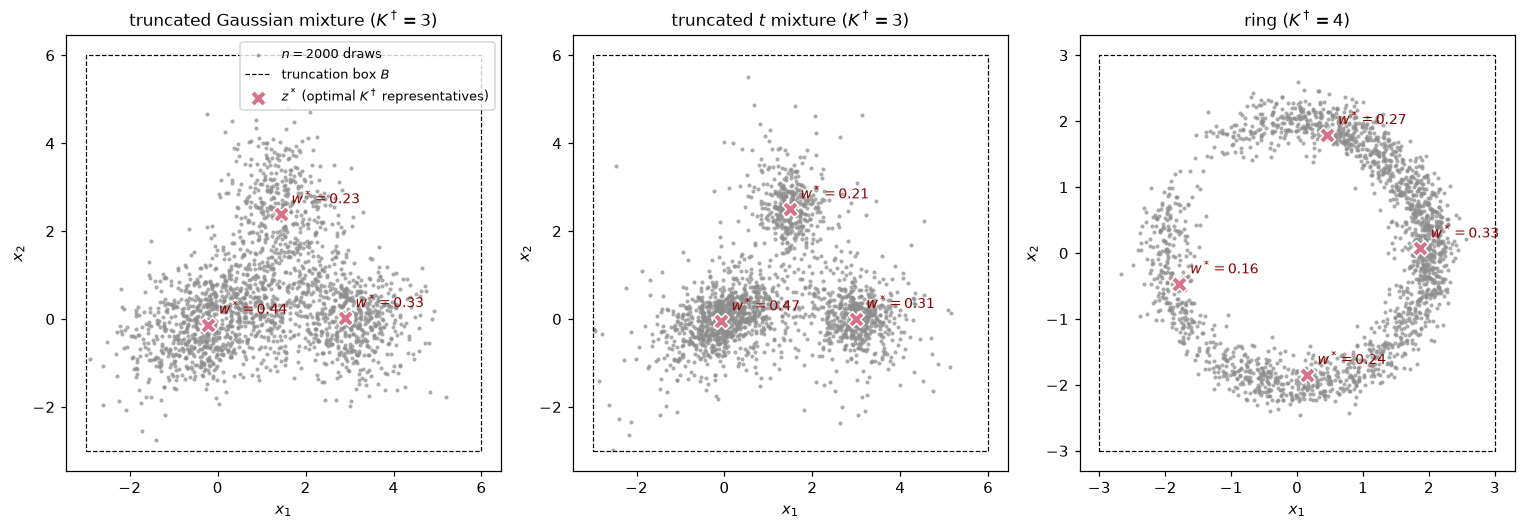

In [2]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4.6))
for a, d in zip(ax, DGPS):
    x = su.gen(np.random.default_rng(0), d, 2000)
    (x0, y0), (x1, y1) = su.BOX[d]
    a.scatter(*x.T, s=3, c='0.55', alpha=0.6, label='$n=2000$ draws')
    a.plot([x0, x1, x1, x0, x0], [y0, y0, y1, y1, y0], 'k--', lw=0.8, label='truncation box $B$')
    a.scatter(*pop[d]['z'].T, marker='X', s=110, c=ACC, edgecolor='w', label=r'$z^*$ (optimal $K^\dagger$ representatives)')
    for j, (z, w) in enumerate(zip(pop[d]['z'], pop[d]['w'])):
        a.annotate(f'$w^*={w:.2f}$', z, xytext=(7, 7), textcoords='offset points', fontsize=9, color='darkred')
    a.set(title=f'{NAME[d]} ($K^\\dagger={pop[d]["K"]}$)', xlabel='$x_1$', ylabel='$x_2$', aspect='equal')
ax[0].legend(loc='upper right')
tidy(fig)

## 1. Choosing $c$

Under the count prior $\Pi_n(K)\propto e^{-ncK}$, Theorem 2 selects $K^\dagger(c)=\arg\min_K(\lambda_0L_K^*+cK)$: a representative is added only if it lowers the population approximation error by more than $c/\lambda_0$. So $c$ is a **resolution**: it states how much reduction in $\lambda_0W_2^2$ an additional representative must buy, and $K^\dagger$ is the coarsest representation at that resolution. It is not an estimate of a "true number of clusters", and the count selected by CoRP is correct only relative to the chosen $c$.

$K^\dagger(c)=K$ exactly for $c\in(\lambda_0(L_K^*-L_{K+1}^*),\,\lambda_0(L_{K-1}^*-L_K^*))$. In this study we fix the intended $K^\dagger$ and take the geometric mean of the two end points,
$$c=\lambda_0\sqrt{(L^*_{K^\dagger-1}-L^*_{K^\dagger})(L^*_{K^\dagger}-L^*_{K^\dagger+1})},$$
which keeps $c$ away from both switch points and so maximizes the margin $\gamma$ on a log scale. The rule uses $P_0$, so it is a simulation device. In an application $c$ is set by the analyst's resolution (or examined over a range of values, as in the right panel below), not estimated.

One column per distribution. First row: $L_K^*$ with a line of slope $-c/\lambda_0$ touching the curve at $K^\dagger$. Second row: $K^\dagger(c)$ for a range of $c$. Third row: $\Pi(K\mid x_{1:n})$ for one data set ($n=1000$) as $c$ varies, from a single set of bridge-sampling runs ($\log Z_K$ for $K=1,\dots,16$, the $K_{\max}$ of the sampler; the count prior enters only through $\Pi(K\mid x)\propto\Pi_n(K)Z_K$). Since $\Pi_n(K)\propto e^{-ncK}$ and $-\log Z_K/n\approx\lambda_0\widehat L_K$, the posterior puts almost all its mass on $\arg\min_K(\lambda_0\widehat L_K+cK)$, and it moves from $K-1$ to $K$ at $c\approx\lambda_0(\widehat L_{K-1}-\widehat L_K)$, the empirical version of the steps in the second row. Each switch is sharp, with width of order $1/n$ in $c$. The triangles mark the switch points, where the posteriors of the two neighboring counts tie: the posterior keeps $K$ representatives exactly as long as the evidence gain $\log Z_K-\log Z_{K-1}$ exceeds $nc$. The posterior is computed for $K\le16$ and reported for $K\le8$, and the grey band collects the mass on $K>8$. A wide band means the count is insensitive to $c$: $K=3$ holds for $c$ from 0.12 to 0.48 (a factor 3.9) for the truncated GMM and from 0.070 to 0.51 (a factor 7.3) for the $t$ mixture, while on the ring $K=4$ holds only from 0.079 to 0.21 (a factor 2.7), since the ring has no well-separated groups.

gmm switch points (c, K, K-1): [(0.024, 8, 7), (0.03, 7, 6), (0.046, 6, 5), (0.051, 5, 4), (0.123, 4, 3), (0.481, 3, 2), (0.921, 2, 1)]
t switch points (c, K, K-1): [(0.023, 7, 6), (0.023, 6, 5), (0.033, 5, 4), (0.07, 4, 3), (0.508, 3, 2), (0.947, 2, 1)]
ring switch points (c, K, K-1): [(0.015, 8, 7), (0.024, 7, 6), (0.053, 6, 5), (0.079, 5, 4), (0.213, 4, 3), (0.401, 3, 2), (0.956, 2, 1)]


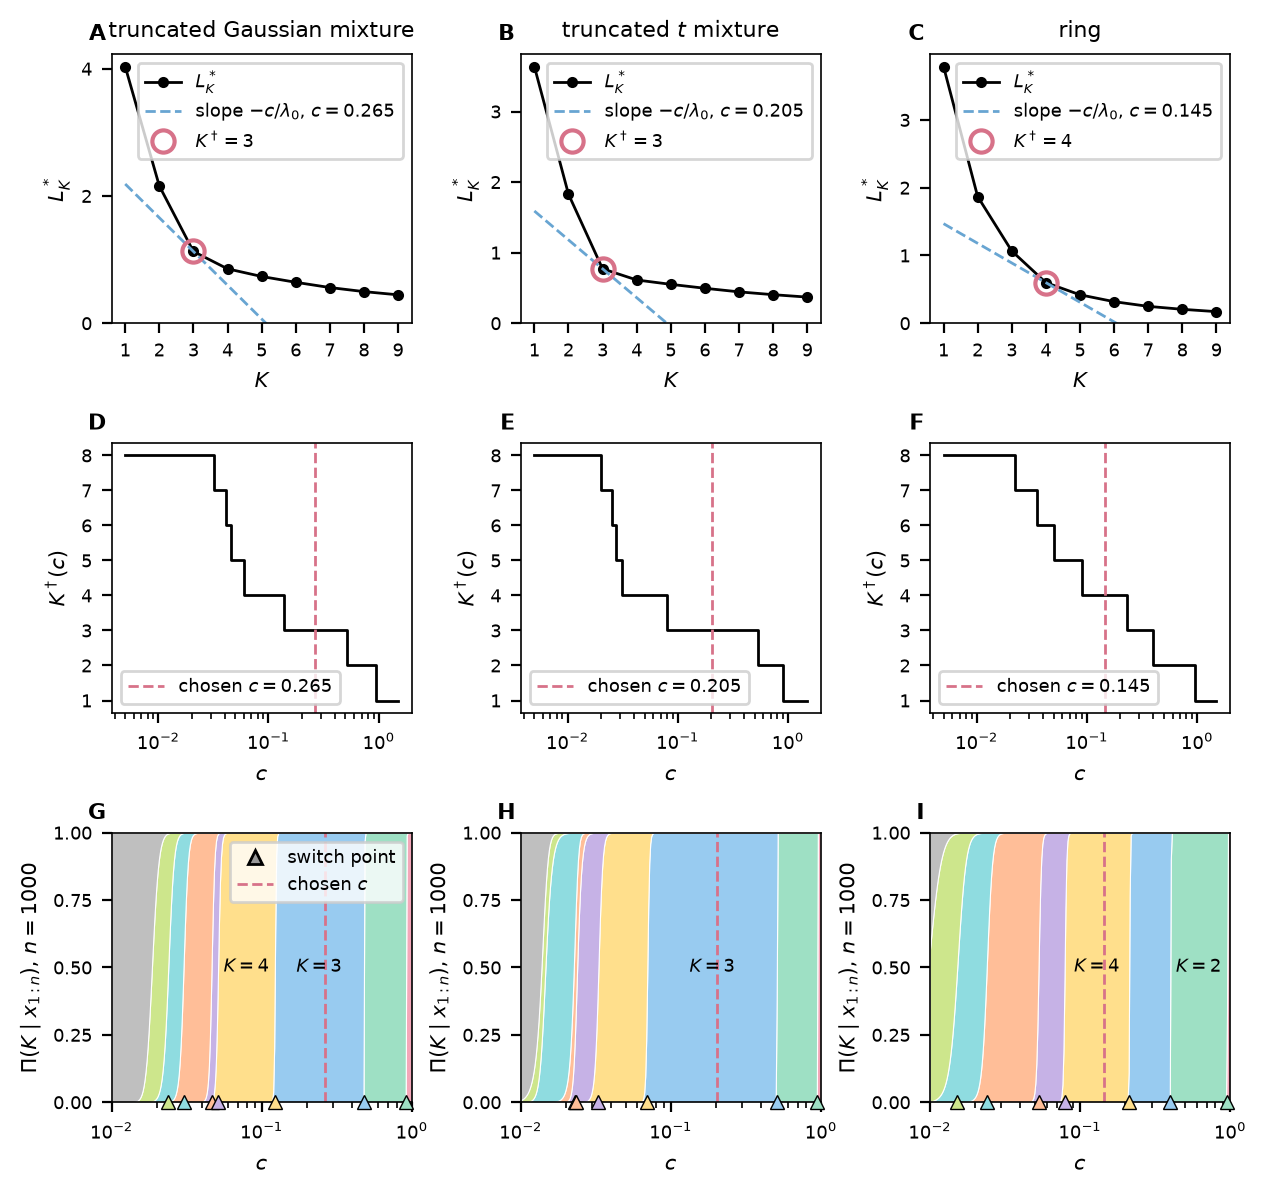

In [3]:
def critical(lz, n, cs):
    # switch points of the posterior mode of K (over all computed K) as c increases, reported for larger K <= 8:
    # (c, larger K, smaller K), where the two posteriors tie
    ks = np.array(sorted(lz))
    mode = [ks[np.argmax([lz[k] - n * c * k for k in ks])] for c in cs]
    return [((lz[a] - lz[b]) / (n * (a - b)), a, b) for a, b in zip(mode[:-1], mode[1:]) if a != b and a <= 8]

def count_path(a, lz, n, cs, chosen=None):
    # stacked Pi(K | x) versus c from log Z_K: bands K = 1..8 and one grey band for K > 8, switch-point triangles
    Ks = np.array(sorted(lz))
    lp = np.array([[lz[k] - n * c * k for k in Ks] for c in cs])
    pk = np.exp(lp - logsumexp(lp, 1, keepdims=True))
    pk = np.c_[pk[:, :8], pk[:, 8:].sum(1)]
    a.stackplot(cs, pk.T, colors=[*FILL, GREY], edgecolor='w', lw=0.4)
    for k in range(9):                     # write K inside each band where it holds most of the mass
        m = pk[:, k] > 0.5
        if m.any() and cs[m][-1] / cs[m][0] > 2.2:
            a.text(np.sqrt(cs[m][0] * cs[m][-1]), 0.5, f'$K={k + 1}$' if k < 8 else '$K>8$', ha='center', va='center', fontsize=6.5)
    for cc, k1, k0 in critical(lz, n, cs):
        a.plot(cc, 0, '^', ms=5, c=FILL[k1 - 1], mec='k', mew=0.5, clip_on=False, zorder=6)
    if chosen is not None:
        a.axvline(chosen, c=ACC, ls='--', lw=1)
    a.set(xscale='log', xlim=(cs[0], cs[-1]), ylim=(0, 1))

VC = FILL
with plt.rc_context(PAPER):
    fig, ax = plt.subplots(3, 3, figsize=(W, 6.0))
    Ks = np.arange(1, 10)
    for i, d in enumerate(DGPS):
        P, K, L = pop[d], pop[d]['K'], pop[d]['L']
        a = ax[0, i]
        a.plot(Ks, L, 'o-', c='k', ms=3, label='$L_K^*$')
        a.plot(Ks, L[K - 1] - P['c'] / LAM0 * (Ks - K), '--', c=MCOL['CoRP'], label=f'slope $-c/\\lambda_0$, $c={P["c"]:.3f}$')
        a.plot(K, L[K - 1], 'o', ms=8, mfc='none', mec=ACC, mew=1.5, label=f'$K^\\dagger={K}$')
        a.set(title=NAME[d], xlabel='$K$', ylabel='$L_K^*$', ylim=(0, L[0] * 1.05), xticks=Ks)
        a.legend()
        a = ax[1, i]
        cs = np.geomspace(0.005, 1.5, 400)
        a.step(cs, [np.argmin(LAM0 * L[:8] + c * np.arange(1, 9)) + 1 for c in cs], where='post', c='k')
        a.axvline(P['c'], c=ACC, ls='--', lw=1, label=f'chosen $c={P["c"]:.3f}$')
        a.set(xscale='log', xlabel='$c$', ylabel='$K^\\dagger(c)$', yticks=range(1, 9))
        a.legend()
        a = ax[2, i]
        lz, n = path[d]['logZ'], path[d]['n']
        count_path(a, lz, n, np.geomspace(0.01, 1, 300), P['c'])
        a.set(xlabel='$c$', ylabel=f'$\\Pi(K\\mid x_{{1:n}})$, $n={n}$')
    ax[2, 0].plot([], [], '^', ms=5, c='0.6', mec='k', label='switch point')
    ax[2, 0].plot([], [], '--', c=ACC, label='chosen $c$')
    ax[2, 0].legend(loc='upper right')
    letters(fig); fig.tight_layout(w_pad=0.6, h_pad=0.8)
    save(fig, 'fig_sim_c')
for d in DGPS:
    print(d, 'switch points (c, K, K-1):', [(round(float(c), 3), int(u), int(v)) for c, u, v in critical(path[d]['logZ'], path[d]['n'], np.geomspace(0.01, 1, 300))])

### Prior and posterior of $K$ at each switch point

One figure per distribution and one column per switch point (the triangles above, $n=1000$). Row 1: the one-observation count prior $\Pi_1(K)\propto e^{-cK}$, a geometric distribution truncated to $K\le16$. Row 2: the count prior for $n$ observations, $\Pi_n(K)\propto\Pi_1(K)^n=e^{-ncK}$. Rows 3 to 5: the count posterior $\Pi(K\mid x_{1:n})\propto\Pi_n(K)Z_K$ (computed for $K\le16$, grey bars $K>8$) just below the switch point, at it, and just above it, with $\delta=5/n$.

$\Pi_1$ is mild and close to uniform for small $c$. Its $n$-th power $\Pi_n$ is a point mass at $K=1$, since $\Pi_n(K+1)/\Pi_n(K)=e^{-nc}$. The evidence grows at the same order, $Z_K/Z_{K-1}\approx e^{n\lambda_0(\widehat L_{K-1}-\widehat L_K)}$, so the posterior compares the error reduction per observation, $\lambda_0(\widehat L_{K-1}-\widehat L_K)$, with $c$. For almost every $c$ the posterior is a single spike. A switch point is by definition the one value of $c$ at which two neighboring counts tie, so there, and only there, it splits 1/2 to 1/2. Moving $c$ by $\delta$ changes the log posterior odds of the two counts by $n\delta=5$, which already gives a spike of about $0.99$ on the larger count below the switch point and on the smaller count above it: the transition has width of order $1/n=0.001$ in $c$.

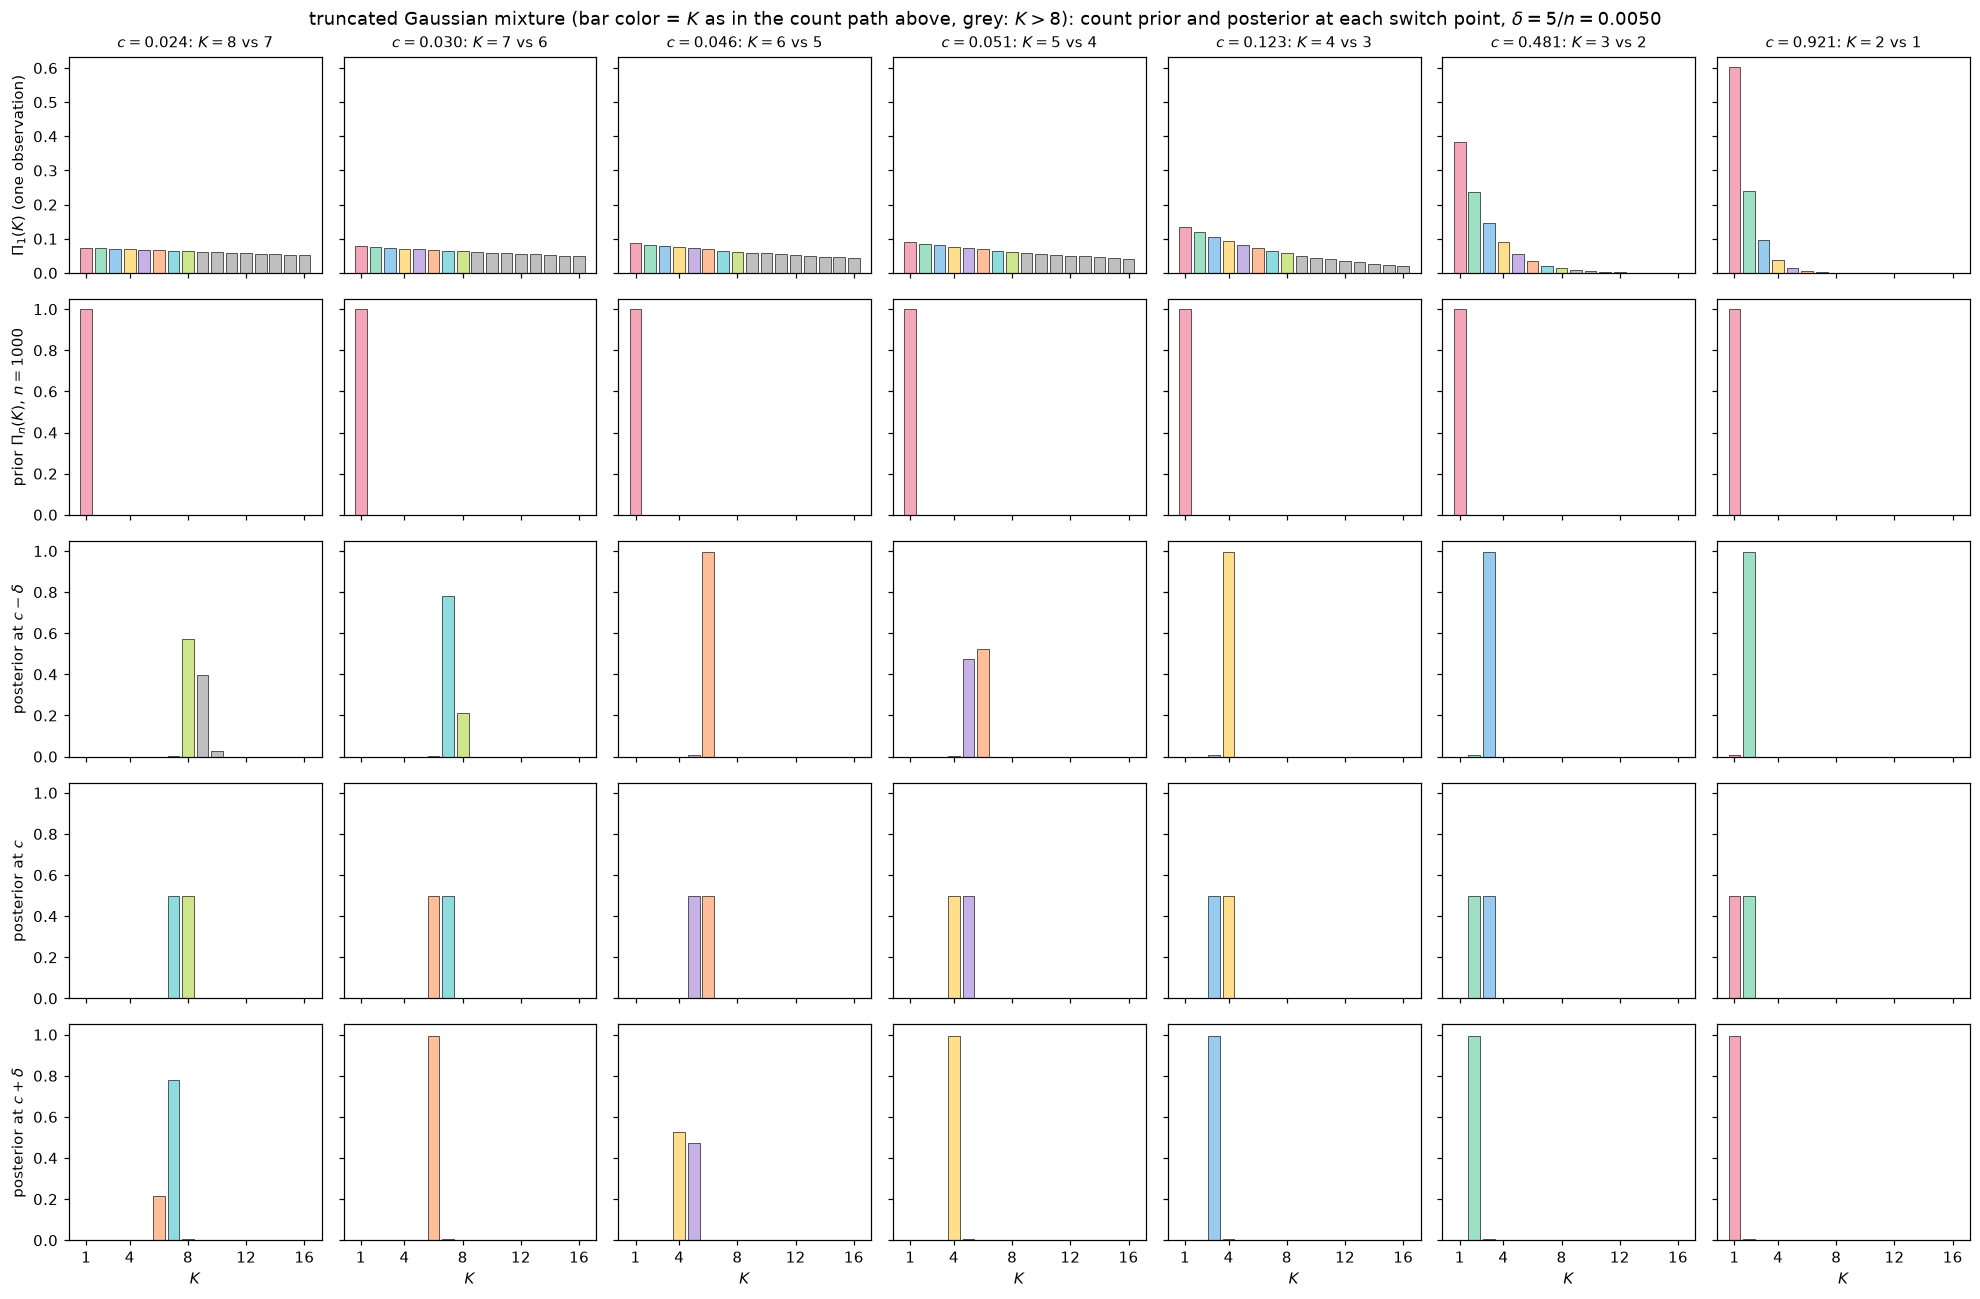

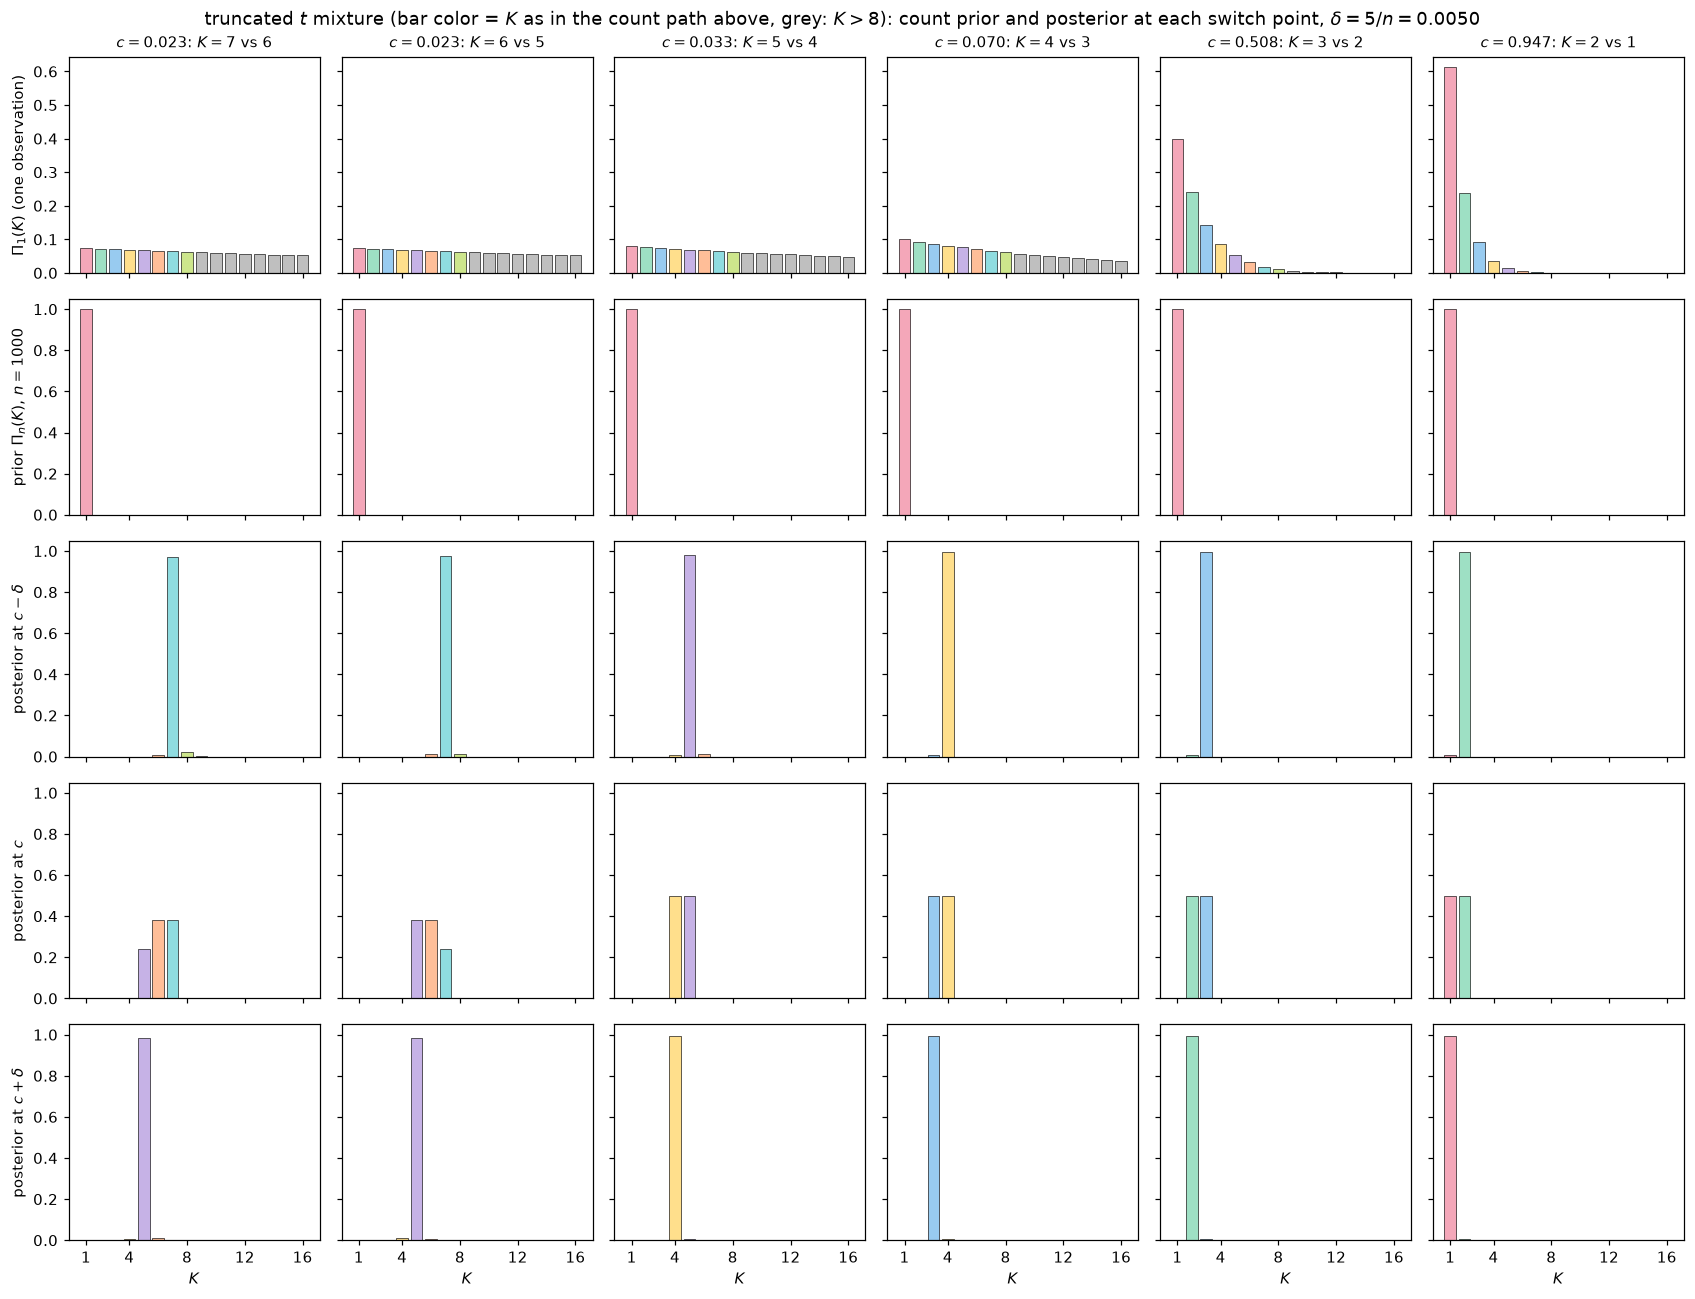

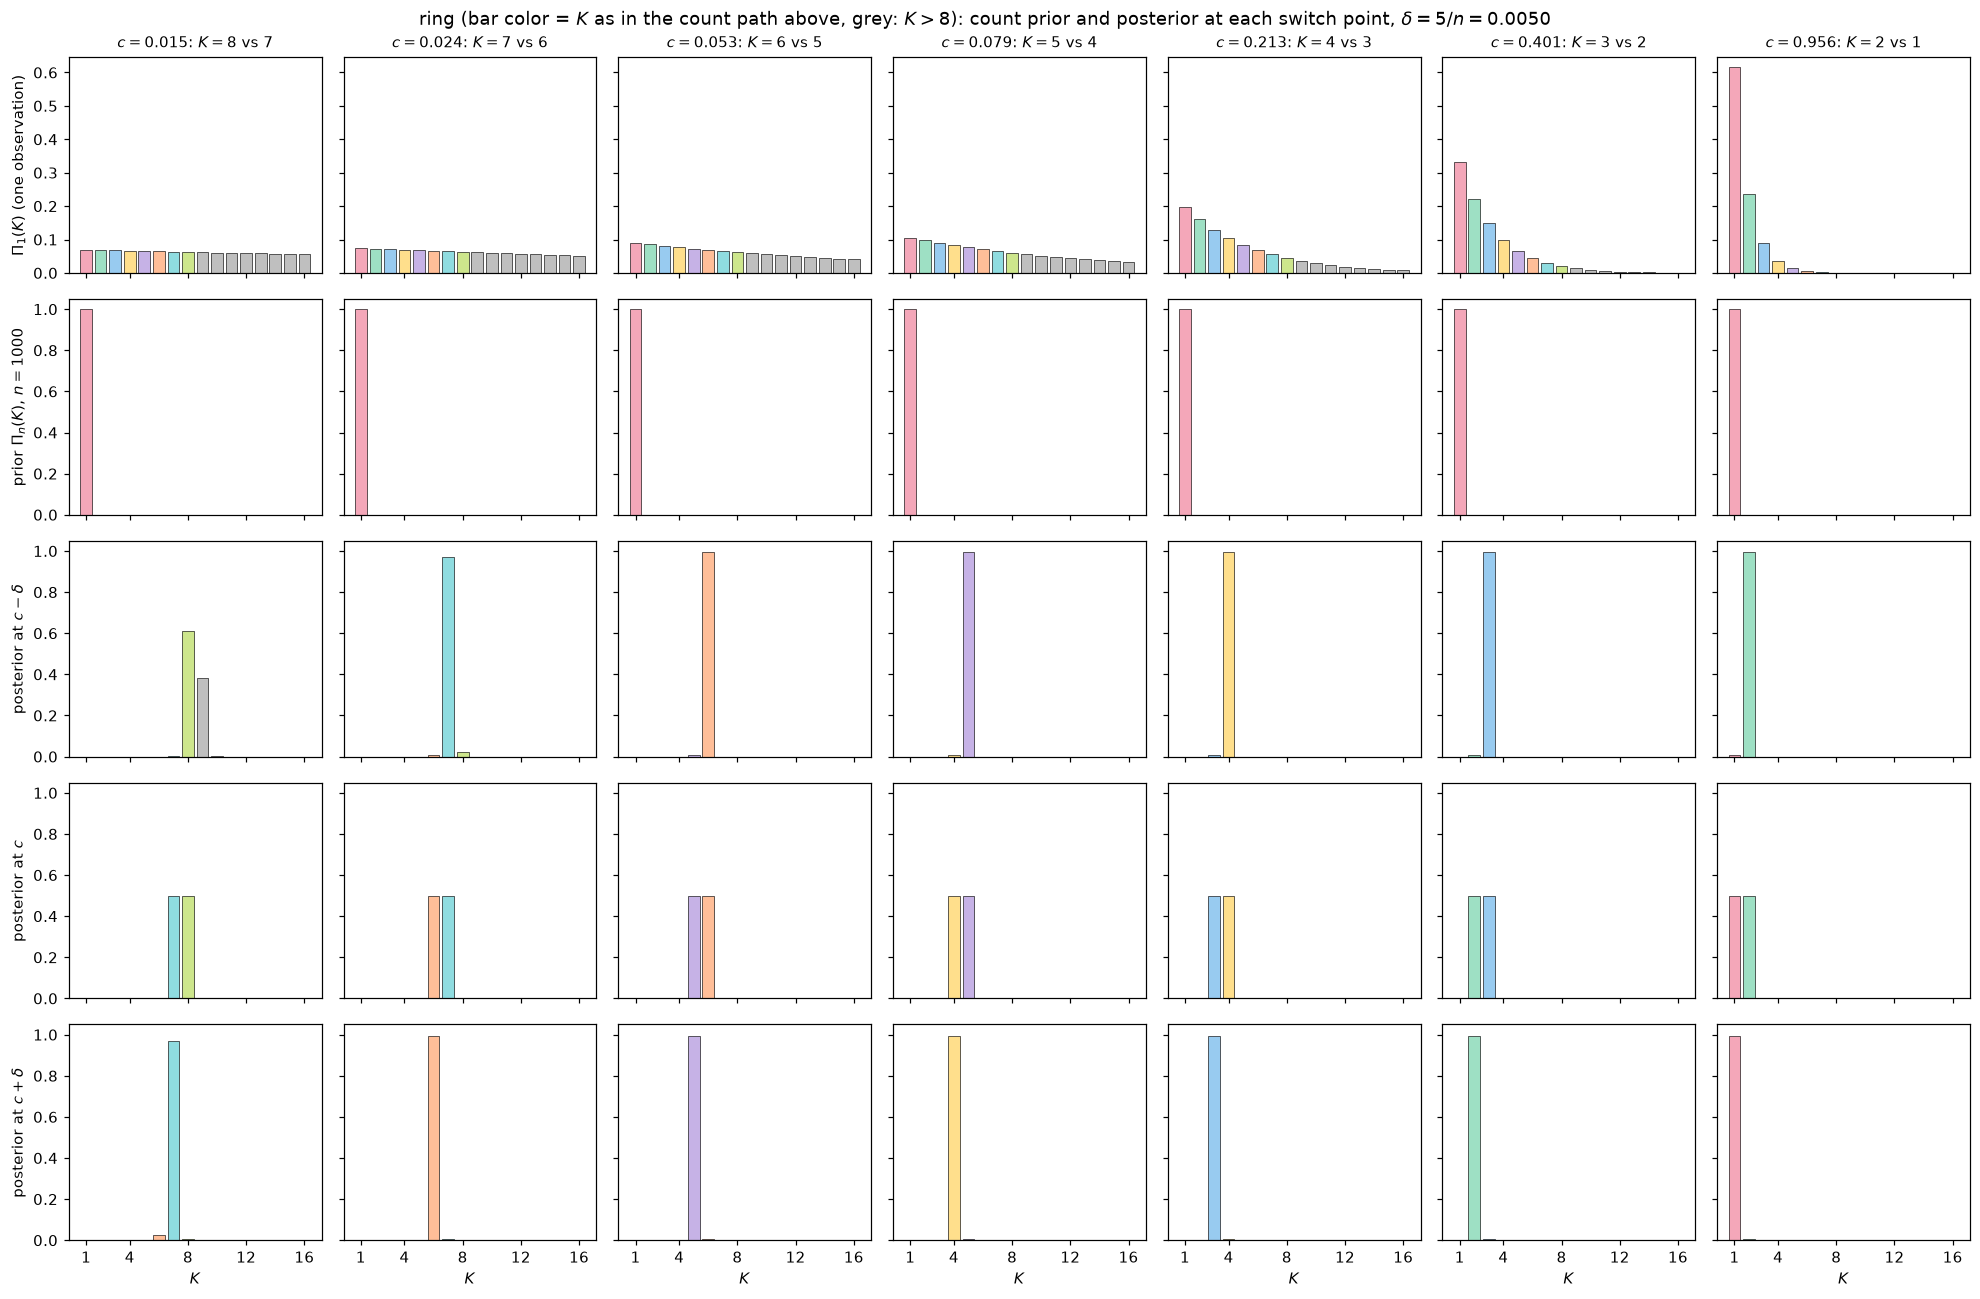

In [4]:
kk = np.arange(1, su.KMAX + 1)
def switch_fig(lz, n, cr, col, title):
    # rows: Pi_1, Pi_n, posterior at c - delta, c, c + delta; one column per switch point (c, larger K, smaller K)
    dl, Kz = 5 / n, np.array(sorted(lz))
    post = lambda c: np.exp((v := np.array([lz[k] - n * c * k for k in Kz])) - logsumexp(v))
    fig, ax = plt.subplots(5, len(cr), figsize=(2.6 * len(cr), 12), sharex=True, sharey='row')
    for j, (cc, k1, k0) in enumerate(cr):
        p1, pn = np.exp(-cc * kk), np.exp(-n * cc * (kk - 1))
        for r, (K, p) in enumerate(((kk, p1 / p1.sum()), (kk, pn / pn.sum()), (Kz, post(cc - dl)), (Kz, post(cc)), (Kz, post(cc + dl)))):
            ax[r, j].bar(K, p, color=[col(k) for k in K], ec='k', lw=0.4)
        ax[0, j].set_title(f'$c={cc:.3f}$: $K={k1}$ vs ${k0}$', fontsize=10)
        ax[4, j].set(xticks=[1, 4, 8, 12, 16], xlabel='$K$')
    for r, lab in enumerate((r'$\Pi_1(K)$ (one observation)', f'prior $\\Pi_n(K)$, $n={n}$', r'posterior at $c-\delta$', r'posterior at $c$', r'posterior at $c+\delta$')):
        ax[r, 0].set_ylabel(lab)
    for r in range(1, 5):
        ax[r, 0].set_ylim(0, 1.05)
    fig.suptitle(f'{title}: count prior and posterior at each switch point, $\\delta=5/n={dl:.4f}$')
    tidy(fig)

for d in DGPS:
    lz, n = path[d]['logZ'], path[d]['n']
    switch_fig(lz, n, critical(lz, n, np.geomspace(0.01, 1, 300)), lambda k: VC[k - 1] if k <= 8 else GREY,
               f'{NAME[d]} (bar color = $K$ as in the count path above, grey: $K>8$)')

## 2. Counts, locations, weights and their uncertainty (one data set per distribution)

For each distribution, one data set, first of size $n=1000$ (from `results/main.pkl` and `results/mfm.pkl`) and then of size $n=200$, the one shown in the paper (computed below). Two figures per sample size: CoRP alone on the $t$ mixture and the ring (the main-text figure) and the three methods on all three distributions (the supplementary figure):

* **CoRP**: posterior draws of the locations given $K^\dagger$ (small dots), 95% regions for each location from the posterior covariance (dashed) and from the sandwich-adjusted draws (solid), and the posterior mean (black dot);
* **$k$-means**: centers at the count chosen by the elbow rule, with 95% regions from 200 bootstrap refits;
* **MFM**: posterior means of the component means at the modal number of filled components $K_+$ of a Bayesian Gaussian mixture with a prior on the number of components ($K\sim\mathrm{Geometric}(0.1)$, Dirichlet(1) weights, normal-inverse-Wishart components, telescoping and split-merge sampler), with 95% posterior regions and weight intervals from the draws given $K_+$.

Red crosses mark $z^*$. The weight next to each representative is its point estimate with a 95% interval (CoRP: sandwich; $k$-means: bootstrap percentiles; MFM: posterior percentiles). MFM means and weights estimate mixture parameters, a different target from $(z^*,w^*)$ whenever the components are not Gaussian.

The CoRP and $k$-means regions look small because they are drawn on axes 6 to 8 units wide, while at $n=1000$ the sampling standard deviation of each coordinate of $\widehat\theta_n$ is only 0.01 to 0.12. They have the right size: over the 60 data sets the sandwich half-widths equal $1.96\,\mathrm{sd}(\widehat\theta_n)$ to within 20%, and so do the $k$-means bootstrap half-widths (Section 4). The posterior regions (dashed) have the right order of magnitude but the wrong shape, from 0.8 to 4.3 times the sampling spread for the locations and 0.3 to 0.7 times for the weights, which is why the weight intervals use the sandwich. The MFM regions are wider where components overlap, because the mean of a Gaussian component that overlaps its neighbors is estimated less precisely than a Voronoi centroid, and where the mixture is misspecified the MFM adds components for the tails or the curvature.

The elbow count depends on the range of counts searched. With $K\le K_{\max}=16$ the Kneedle rule selects $K=4=K^\dagger$ on the ring, and with $K\le8$ it selects $K=3$ in most data sets (Section 3a).

n = 1000: DGP                     K† CoRP mode  k-means  MFM
         truncated Gaussian mixture   3         3        4    3
         truncated $t$ mixture    3         3        3    6
         ring                     4         4        4    8


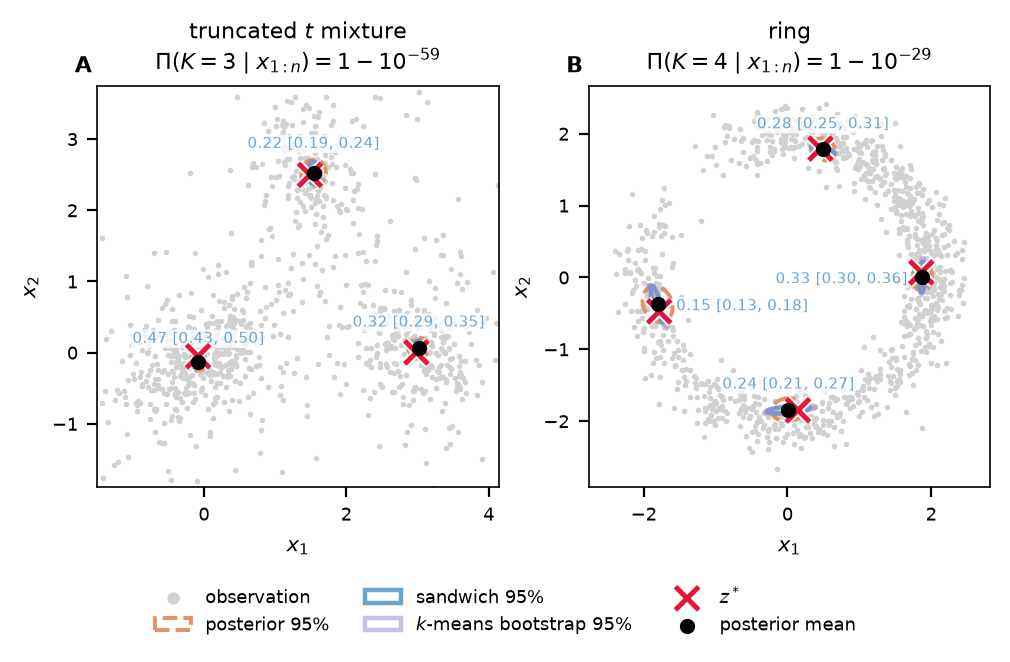

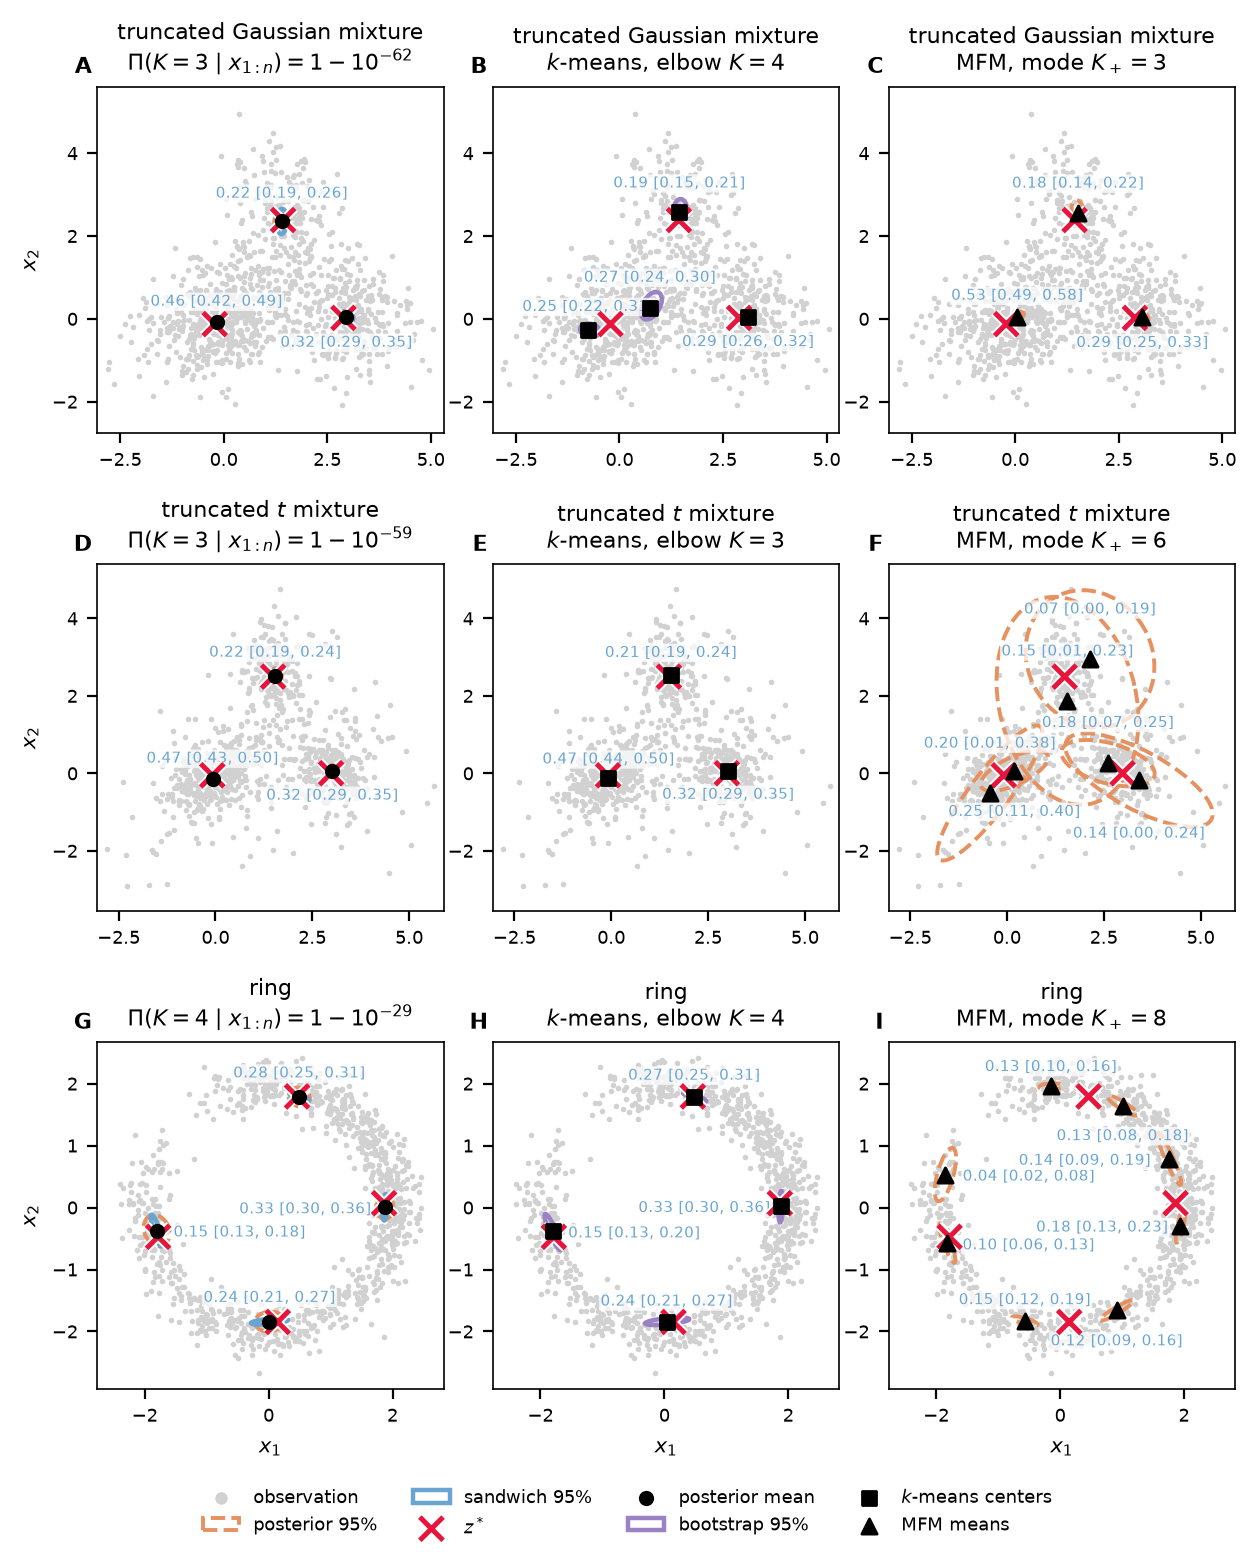

In [5]:
def ellipse(a, D, **kw):
    # 95% normal-theory region of a 2-d cloud of draws
    m, S = D.mean(0), np.cov(D.T)
    e, U = np.linalg.eigh(S)
    r = np.sqrt(chi2.ppf(0.95, 2) * e)
    a.add_patch(Ellipse(m, 2 * r[1], 2 * r[0], angle=np.degrees(np.arctan2(U[1, 1], U[0, 1])), fill=False, **kw))

def km_boot(x, K, B=200, seed=0):
    rng = np.random.default_rng(seed)
    M = Model(x)
    z = quantizer(M, K)[1]
    Z, Wb = [], []
    for _ in range(B):
        Mb = Model(x[rng.integers(len(x), size=len(x))])
        zb = quantizer(Mb, K, n_init=3, seed=int(rng.integers(1 << 30)))[1]
        zb = zb[relabel(z, zb)]
        Z.append(zb); Wb.append(Mb.voronoi_masses(zb))
    return z, M.voronoi_masses(z), np.array(Z), np.array(Wb)

def wlabels(a, Z, D, W, lo, hi, color):
    # one weight label per representative (locations Z, draws D of shape B x K x 2): above or below it, clear of its 95%
    # region, inside the window (set before) and apart from the labels already placed; beside it as a fallback
    px, T = a.figure.dpi / 72, a.transData.transform
    (X0, Y0), (X1, Y1) = T((a.get_xlim()[0], a.get_ylim()[0])), T((a.get_xlim()[1], a.get_ylim()[1]))
    E = np.minimum(2.5 * D.std(0) * (T((1, 1)) - T((0, 0))) / px, 12) + 3   # half-extents of the regions in points (capped), plus a gap
    placed = []
    for k in np.argsort(Z[:, 0]):
        txt = f'{W[k]:.2f} [{lo[k]:.2f}, {hi[k]:.2f}]'
        w, h, (x, y) = 2.6 * len(txt), 7, T(Z[k])                            # label size in points
        side, fb = (1 if x < (X0 + X1) / 2 else -1), None
        for dx, dy, ha in [(0, E[k, 1], 'center'), (0, -E[k, 1] - h, 'center'),
                           (side * E[k, 0], -h / 2, 'left' if side > 0 else 'right'), (-side * E[k, 0], -h / 2, 'right' if side > 0 else 'left'),
                           (0, E[k, 1] + h + 1, 'center'), (0, -E[k, 1] - 2 * h - 1, 'center')]:
            x0 = x + (dx - {'center': w / 2, 'left': 0, 'right': w}[ha]) * px
            b = np.array([x0, y + dy * px, x0 + w * px, y + (dy + h) * px])
            inside = X0 <= b[0] and b[2] <= X1 and Y0 <= b[1] and b[3] <= Y1
            fb = fb or (inside and (dx, dy, ha, b))
            if inside and not any(b[0] < q[2] and q[0] < b[2] and b[1] < q[3] and q[1] < b[3] for q in placed):
                break
        else:
            dx, dy, ha, b = fb or (0, E[k, 1], 'center', b)
        placed.append(b)
        a.annotate(txt, Z[k], xytext=(dx, dy), textcoords='offset points', fontsize=5.5, color=color, ha=ha, va='bottom',
                   bbox=dict(boxstyle='round,pad=0.1', fc='w', ec='none', alpha=0.75)).set_in_layout(False)

ZOOM = {'gmm': 0.2, 't': 0.2, 'ring': 0.0}                                # quantile trimmed on each side of the allocation panels (none for the ring)
FIG1_ZOOM = {'t': 2.0, 'ring': 0.0}                                       # Figure 1: the t panel shows the central 96% of the data

def ext(D):
    # bounding-box corners of the 95% regions of draws D (B x K x 2), so that a window built on them contains the regions
    m, s = D.mean(0), D.std(0)
    return np.r_[m - 2.5 * s, m + 2.5 * s]

def window(x, q=1.0, pad=0.25):
    # square plotting window around the bulk of the data (quantiles q and 100 - q), so that panels have the same shape
    lo, hi = np.percentile(x, [q, 100 - q], axis=0)
    c, r = (lo + hi) / 2, (hi - lo).max() / 2 + pad
    return dict(xlim=(c[0] - r, c[0] + r), ylim=(c[1] - r, c[1] + r), aspect='equal')

def cross(a, z, label=None):
    # z* as thin crosses
    a.scatter(*z.T, marker='x', s=70, c=STAR, linewidths=1.8, zorder=5, label=label,
              path_effects=[pe.Stroke(linewidth=3.2, foreground='w'), pe.Normal()])

def corp_panel(a, o, P, name, extra=(), boot=None, q=0.0):
    # data, posterior and sandwich 95% regions of each location given K†, weights with sandwich intervals, z*, and the
    # k-means bootstrap regions at K† if boot (B x K x 2) is given; returns the plotting window, which covers the data,
    # the regions and the points in extra
    K, n, x = P['K'], o['n'], o['x']
    kd = 2 * K
    a.scatter(*x.T, s=4, c='0.82', lw=0, label='observation')
    zr, za = o['raw'][:, :kd].reshape(-1, K, 2), o['adj'][:, :kd].reshape(-1, K, 2)
    wa, wr = (np.c_[D[:, kd:], 1 - D[:, kd:].sum(1)] for D in (o['adj'], o['raw']))
    win = window(np.concatenate([x, ext(zr), ext(za), *extra]), q)         # q: quantile trimmed on each side (zoom)
    a.set(**win)
    for j in range(K):
        ellipse(a, zr[:, j], ec=LINE[5], ls='--', lw=1.4, label='posterior 95%' if j == 0 else None)
        ellipse(a, za[:, j], ec=MCOL['CoRP'], lw=1.6, label='sandwich 95%' if j == 0 else None)
        if boot is not None:
            ellipse(a, boot[:, j], ec=LINE[4], lw=1.6, alpha=0.5, zorder=3, label='$k$-means bootstrap 95%' if j == 0 else None)   # drawn over the sandwich region
    wlabels(a, zr.mean(0), np.concatenate([zr, za]), wr.mean(0), *np.percentile(wa, [2.5, 97.5], axis=0), MCOL['CoRP'])
    cross(a, P['z'], '$z^*$')
    a.scatter(*zr.mean(0).T, c='k', s=20, zorder=6, label='posterior mean')
    lp = {k: v - n * P['c'] * k for k, v in o['logZ'].items()}       # log posterior of K up to a constant
    e10 = (logsumexp([v for k, v in lp.items() if k != K]) - logsumexp(list(lp.values()))) / np.log(10)
    pk = f'1-10^{{{e10:.0f}}}' if e10 < -3 else f'{1 - 10 ** e10:.3f}'
    a.set_title(f'{name}\n$\\Pi(K={K}\\mid x_{{1:n}})={pk}$')
    return win

def big_obs(leg):
    # enlarge only the legend marker of the observations, which are drawn tiny in the panels
    for h, t in zip(leg.legend_handles, leg.get_texts()):
        if t.get_text() == 'observation':
            h.set_sizes([20])

def one_data_set(n, mfm_fit, ill=None, paper=False):
    # Section 2 figures and count table for the rep-0 data set of size n; mfm_fit: MFM fit per DGP (sim_utils.mfm_job),
    # ill: CoRP results per DGP (default: read from results/main.pkl); paper: save the two figures to figures/
    ill = ill or {o['dgp']: o for o in main if o['n'] == n and o['rep'] == 0}
    with plt.rc_context(PAPER):
        fig, ax = plt.subplots(1, 2, figsize=(W * 0.78, 2.75))             # CoRP alone, t mixture and ring (the main-text figure)
        for a, d in zip(ax, DGPS[1:]):
            Zb = km_boot(ill[d]['x'], pop[d]['K'])[2]                         # k-means bootstrap at K†, the frequentist benchmark
            corp_panel(a, ill[d], pop[d], NAME[d], (ext(Zb),), Zb, q=FIG1_ZOOM[d])
            a.set(xlabel='$x_1$', ylabel='$x_2$')
        big_obs(fig.legend(*ax[0].get_legend_handles_labels(), loc='lower center', ncol=3, bbox_to_anchor=(0.5, -0.16), frameon=False))
        letters(fig); fig.tight_layout(w_pad=0.6, pad=0.3)
        if paper:
            save(fig, 'fig_sim_main')
        fig, ax = plt.subplots(3, 3, figsize=(W, 7.8))                     # the three methods
        rows = []
        for i, d in enumerate(DGPS):
            o, P, K = ill[d], pop[d], pop[d]['K']
            x, Kkm, G = o['x'], o['K_km'], mfm_fit[d]
            zk, wk, Zb, Wb = km_boot(x, Kkm)
            win = corp_panel(ax[i, 0], o, P, NAME[d], (ext(Zb), ext(G['post_m'])))
            for a in ax[i, 1:]:
                a.scatter(*x.T, s=4, c='0.82', lw=0)
                cross(a, P['z'], '$z^*$')
                a.set(**win)
            ax[i, 0].set_ylabel('$x_2$')
            for j in range(Kkm):
                ellipse(ax[i, 1], Zb[:, j], ec=LINE[4], lw=1.6, label='bootstrap 95%' if j == 0 else None)
            wlabels(ax[i, 1], zk, Zb, wk, *np.percentile(Wb, [2.5, 97.5], axis=0), MCOL['CoRP'])
            ax[i, 1].scatter(*zk.T, c='k', marker='s', s=22, zorder=6, label='$k$-means centers')
            ax[i, 1].set_title(f'{NAME[d]}\n$k$-means, elbow $K={Kkm}$')
            for j in range(G['K']):
                ellipse(ax[i, 2], G['post_m'][:, j], ec=LINE[5], ls='--', lw=1.4, label='posterior 95%' if j == 0 else None)
            wlabels(ax[i, 2], G['m'], G['post_m'], G['p'], *np.percentile(G['post_p'], [2.5, 97.5], axis=0), MCOL['CoRP'])
            ax[i, 2].scatter(*G['m'].T, c='k', marker='^', s=30, zorder=6, label='MFM means')
            ax[i, 2].set_title(f'{NAME[d]}\nMFM, mode $K_+={G["K"]}$')
            rows.append((NAME[d], K, Kkm, G['K']))
        H = {}
        for a in ax[0]:
            for h, l in zip(*a.get_legend_handles_labels()):
                H.setdefault(l, h)
        for a in ax[2]:
            a.set_xlabel('$x_1$')
        big_obs(fig.legend(H.values(), H.keys(), loc='lower center', ncol=4, bbox_to_anchor=(0.5, 0.0), frameon=False))
        letters(fig); fig.tight_layout(w_pad=0.2, h_pad=1.0, rect=(0, 0.045, 1, 1))
        if paper:
            save(fig, 'fig_sim_methods')
    print(f'n = {n}: {"DGP":22s} {"K†":>3s} {"CoRP mode":>9s} {"k-means":>8s} {"MFM":>4s}')
    for r, d in zip(rows, DGPS):
        print(f'         {r[0]:22s} {r[1]:3d} {max(ill[d]["pK"], key=ill[d]["pK"].get):9d} {r[2]:8d} {r[3]:4d}')

one_data_set(1000, mfm_ill)

### The same comparison at $n=200$ (the figures of the paper)

$n=200$ is below the sample sizes of the study, so for the rep-0 data set of each distribution the CoRP fit (`sim_utils.job`: bridge sampling, sandwich calibration and $k$-means bootstrap) and the MFM fit (`sim_utils.mfm_job`) are computed here (under a minute). Everything is seeded, so the figures are reproducible.

n = 200: DGP                     K† CoRP mode  k-means  MFM
         truncated Gaussian mixture   3         3        4    3
         truncated $t$ mixture    3         3        3    5
         ring                     4         4        4    6
Pi(K | x) at n = 200: {'gmm': {3: 1.0}, 't': {3: 1.0}, 'ring': {4: 1.0}}


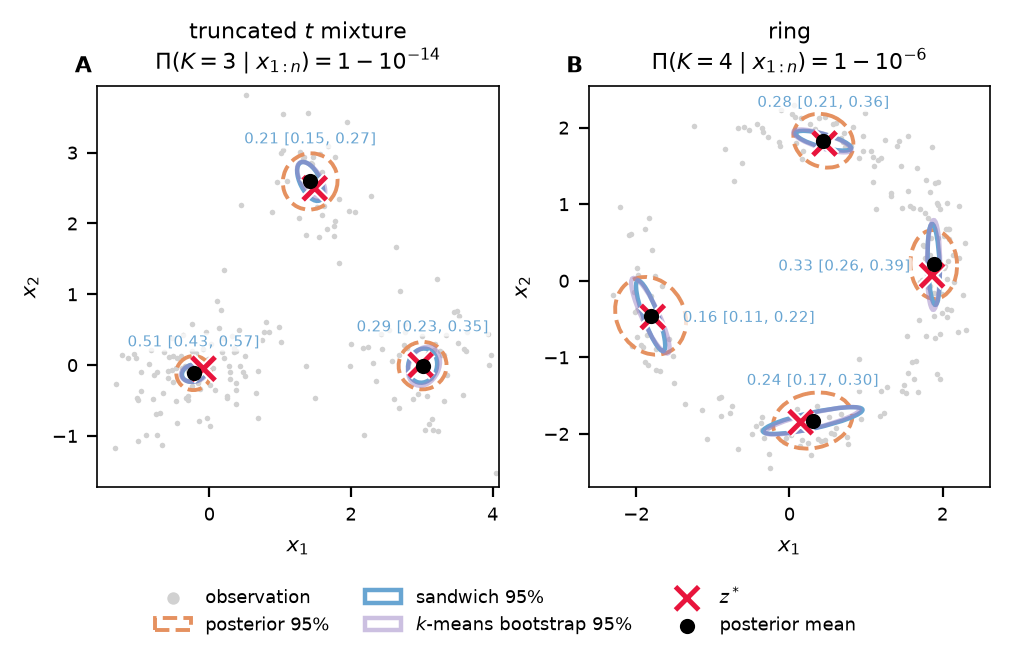

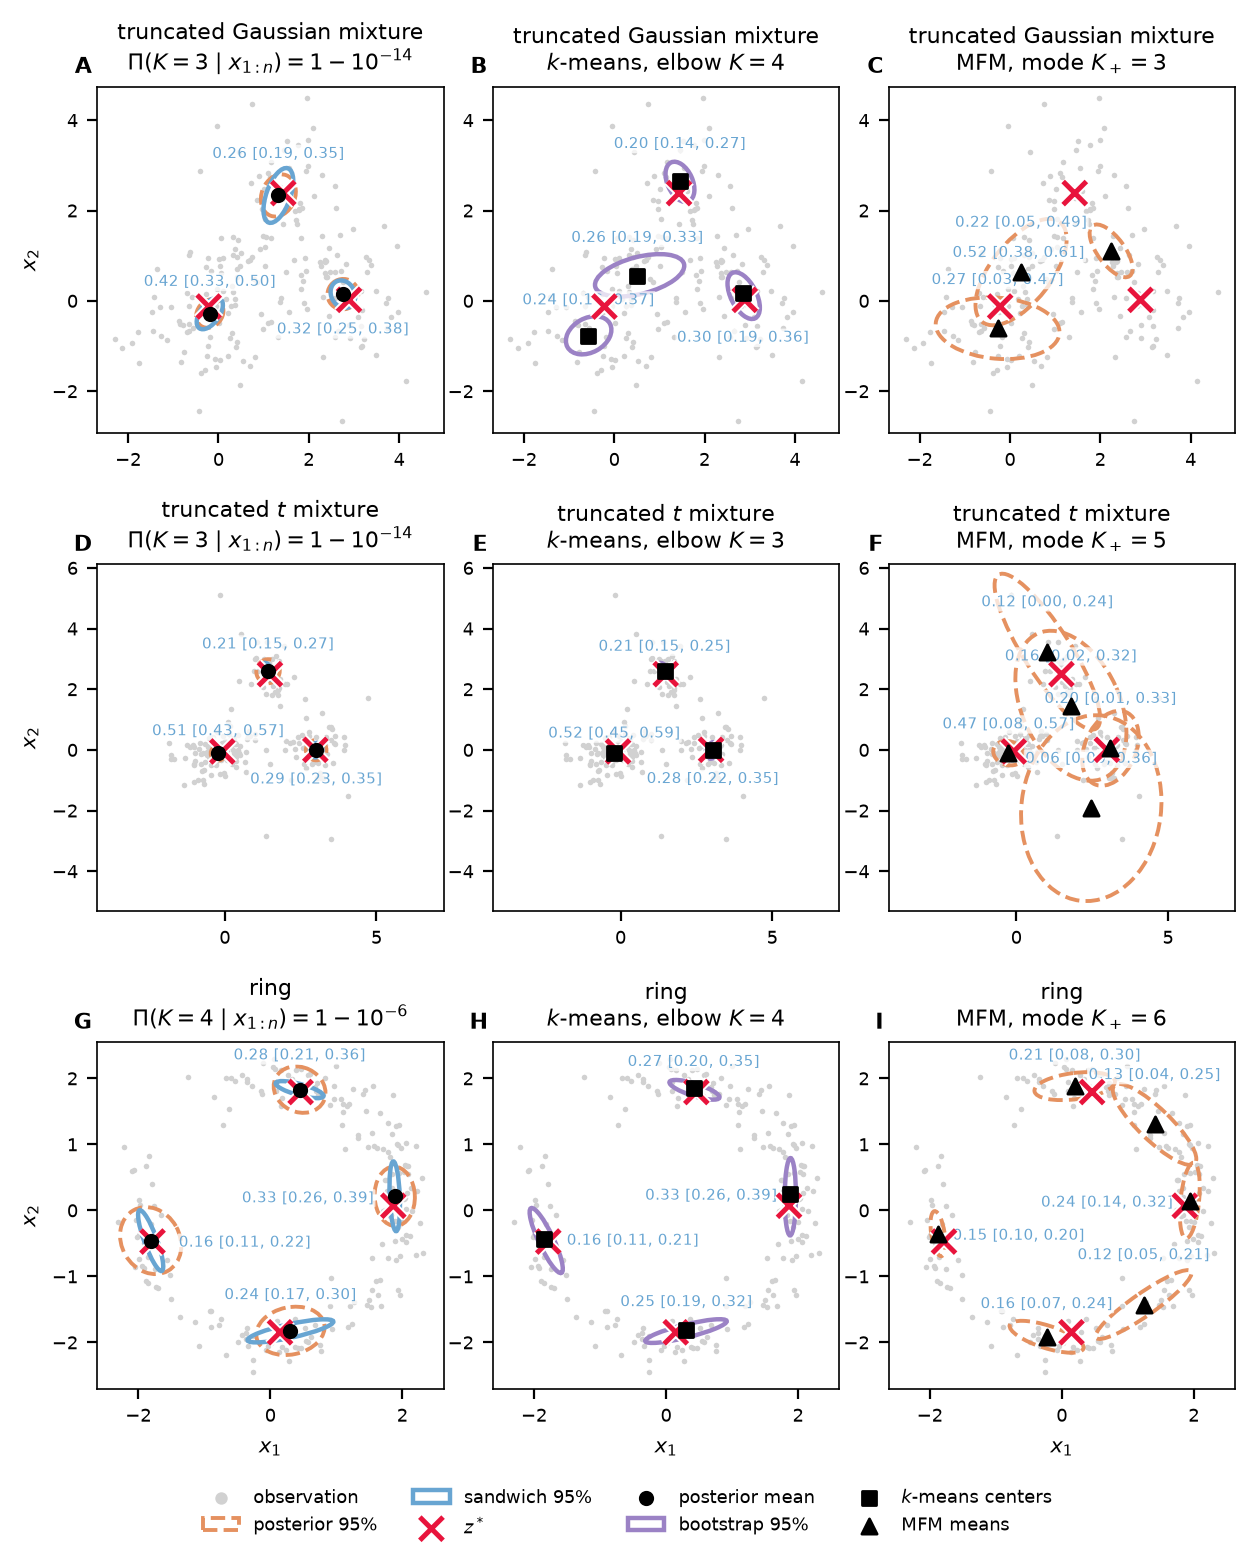

In [6]:
from multiprocessing import get_context
with get_context('fork').Pool(6) as pool:
    w200 = pool.map_async(su.job, [(d, 200, 0, pop[d], True) for d in DGPS])
    mfm200 = {g['dgp']: g for g in pool.map(su.mfm_job, [(d, 200, 0, None) for d in DGPS])}
    w200 = {o['dgp']: o for o in w200.get()}
one_data_set(200, mfm200, w200, paper=True)
print('Pi(K | x) at n = 200:', {d: {int(k): round(float(v), 3) for k, v in w200[d]['pK'].items() if v > 1e-3} for d in DGPS})

## 3. Varying the sample size

$n\in\{250,500,1000,2000,4000\}$, 20 data sets per $(\text{DGP},n)$ with the full bridge-sampling count posterior, and 60 data sets for the conditional summaries in Section 4.

### 3a. Selected counts

CoRP reports the posterior mode of $K$, $k$-means the elbow count, GMM the BIC count and MFM the posterior mode of the number of filled components $K_+$. The bars show how often each count is selected. A method whose selected count drifts with $n$ has no fixed target at the scale of the data.

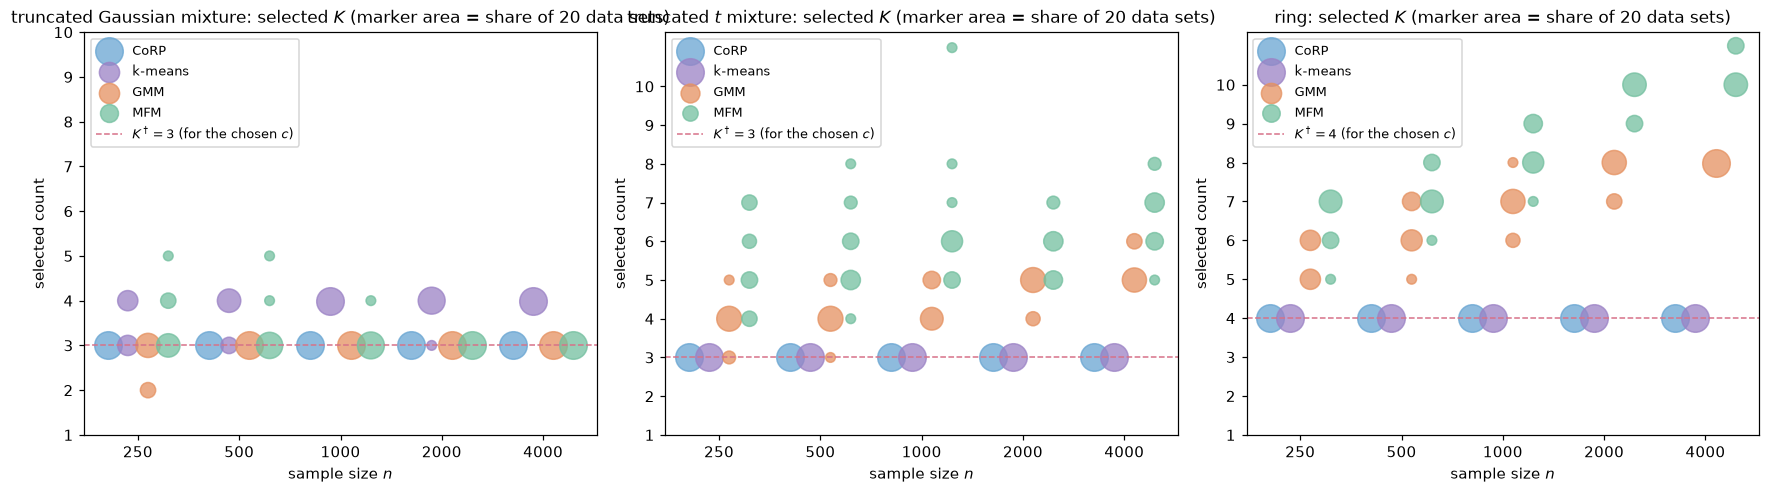

In [7]:
full = [o for o in main if 'pK' in o]
sel = {'CoRP': lambda o: max(o['pK'], key=o['pK'].get), 'k-means': lambda o: o['K_km'], 'GMM': lambda o: o['K_gmm'],
       'MFM': lambda o: K_mfm[o['dgp'], o['n'], o['rep']]}
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
for a, d in zip(ax, DGPS):
    for m, (name, f) in enumerate(sel.items()):
        for k_n, n in enumerate(NS):
            Ks = np.array([f(o) for o in full if o['dgp'] == d and o['n'] == n])
            vals, cnt = np.unique(Ks, return_counts=True)
            a.scatter(np.full(len(vals), k_n + (m - 1.5) * 0.2), vals, s=25 + 300 * cnt / len(Ks), color=MCOL[name], alpha=0.75,
                      label=name if k_n == 0 else None)
    a.axhline(pop[d]['K'], c=ACC, ls='--', lw=1, label=f'$K^\\dagger={pop[d]["K"]}$ (for the chosen $c$)')
    a.set(xticks=range(len(NS)), xticklabels=NS, xlabel='sample size $n$', ylabel='selected count', title=f'{NAME[d]}: selected $K$ (marker area = share of 20 data sets)',
          yticks=range(1, 11))
    a.legend(loc='upper left')
tidy(fig)

### 3a (continued). The largest count $K_{\max}$

Both CoRP and the elbow rule search $K\le K_{\max}=16$. The figure compares this with $K_{\max}=8$.

* Left: the $k$-means cost $\widehat L_K$ of the 20 data sets at $n=1000$ (gray, the first one in black) and the Kneedle elbow of the first data set under each $K_{\max}$. Kneedle rescales both axes to $[0,1]$ over the range searched and takes the point farthest from the chord, so a longer flat tail moves the elbow.
* Middle: the elbow count of the 20 data sets per $n$ under $K_{\max}=8$ (hatched) and $K_{\max}=16$.
* Right: $\log_{10}\Pi(K\mid x_{1:n})$ of CoRP on the first data set at $n=1000$, from $\log Z_K$ for $K\le16$, normalized over $K\le8$ (circles) and over $K\le16$ (dots). The dotted line marks the last count the bridge sampler evaluates before its stopping rule applies.

The bridge sampler evaluates $K=1,2,\dots$ and stops once two consecutive counts have negligible mass, so $K_{\max}$ enters only as an upper limit that is never reached here, and a run with $K_{\max}=8$ performs the same computations (checked by rerunning six data sets with $K_{\max}=8$: identical output).

gmm: elbow counts {K: data sets} over the 100 data sets, K_max = 8: {np.int64(3): np.int64(100)} K_max = 16: {np.int64(3): np.int64(17), np.int64(4): np.int64(83)} | largest count evaluated by the bridge sampler: 5 | log10 Pi(K > 8 | x), n = 1000: -564
t: elbow counts {K: data sets} over the 100 data sets, K_max = 8: {np.int64(3): np.int64(100)} K_max = 16: {np.int64(3): np.int64(100)} | largest count evaluated by the bridge sampler: 5 | log10 Pi(K > 8 | x), n = 1000: -456
ring: elbow counts {K: data sets} over the 100 data sets, K_max = 8: {np.int64(3): np.int64(94), np.int64(4): np.int64(6)} K_max = 16: {np.int64(4): np.int64(100)} | largest count evaluated by the bridge sampler: 6 | log10 Pi(K > 8 | x), n = 1000: -236


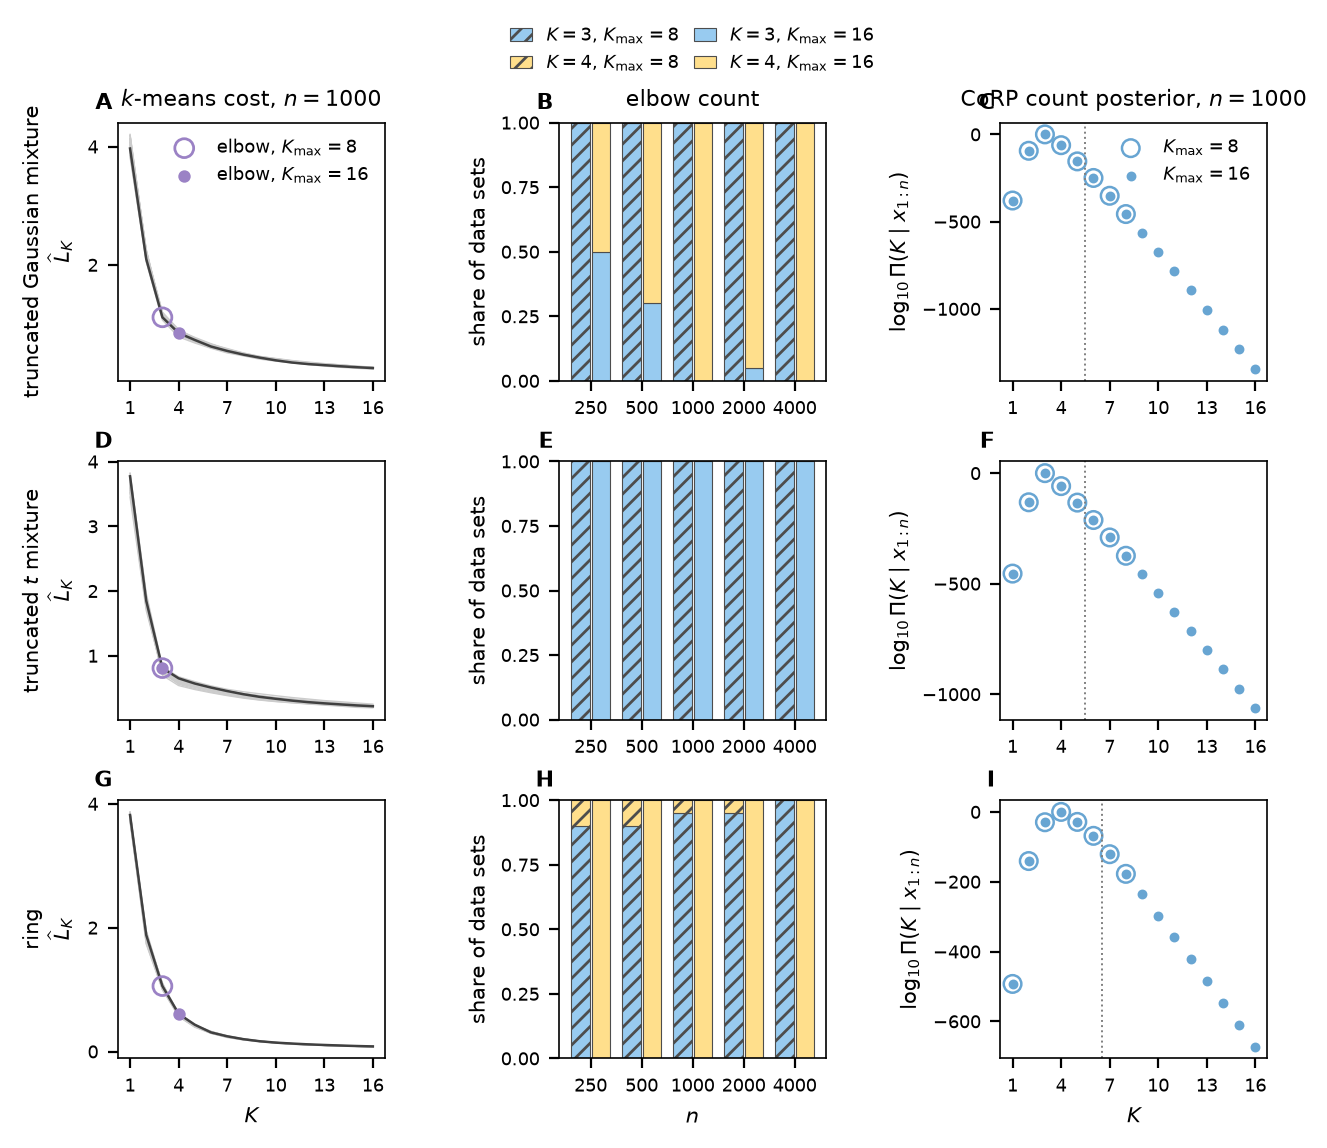

In [8]:
KM = (8, su.KMAX)                                            # the two values of K_max
with plt.rc_context(PAPER):
    fig, ax = plt.subplots(3, 3, figsize=(W, 5.6))
    for i, d in enumerate(DGPS):
        O = [o for o in full if o['dgp'] == d]
        a, o0 = ax[i, 0], next(o for o in O if o['n'] == 1000 and o['rep'] == 0)
        for o in O:
            if o['n'] == 1000:
                a.plot(kk, o['Lhat'], color='0.8', lw=0.5, zorder=1)
        a.plot(kk, o0['Lhat'], color='0.25', lw=0.9, zorder=2)
        for m, ms, fc, zo in zip(KM, (46, 12), ('none', LINE[4]), (4, 3)):
            k = su.elbow(o0['Lhat'][:m])
            a.scatter(k, o0['Lhat'][k - 1], s=ms, facecolor=fc, edgecolor=LINE[4], lw=1.0, zorder=zo, label=f'elbow, $K_{{\\max}}={m}$')
        a.set(xticks=kk[::3], ylabel=NAME[d] + '\n$\\widehat L_K$')
        a = ax[i, 1]
        for j, n in enumerate(NS):
            for s, m in zip((-0.2, 0.2), KM):
                Ke, b = np.array([su.elbow(o['Lhat'][:m]) for o in O if o['n'] == n]), 0
                for k in (3, 4):
                    h = np.mean(Ke == k)
                    a.bar(j + s, h, 0.36, bottom=b, color=FILL[k - 1], edgecolor='0.3', lw=0.4, hatch='' if m == su.KMAX else '////',
                          label=f'$K={k}$, $K_{{\\max}}={m}$' if j == 0 else None)
                    b += h
        a.set(xticks=range(len(NS)), xticklabels=NS, ylim=(0, 1), ylabel='share of data sets')
        a, lz = ax[i, 2], path[d]['logZ']
        lp = np.array([lz[k] - path[d]['n'] * pop[d]['c'] * k for k in kk])
        for m, ms, fc in zip(KM, (40, 7), ('none', LINE[2])):
            a.scatter(kk[:m], (lp[:m] - logsumexp(lp[:m])) / np.log(10), s=ms, facecolor=fc, edgecolor=LINE[2], lw=0.9, label=f'$K_{{\\max}}={m}$')
        a.axvline(max(o0['logZ']) + 0.5, color='0.5', ls=':', lw=0.7)
        a.set(xticks=kk[::3], ylabel='$\\log_{10}\\Pi(K\\mid x_{1:n})$')
        print(f'{d}: elbow counts {{K: data sets}} over the 100 data sets, K_max = 8:', dict(zip(*map(list, np.unique([su.elbow(o["Lhat"][:8]) for o in O], return_counts=True)))),
              'K_max = 16:', dict(zip(*map(list, np.unique([o["K_km"] for o in O], return_counts=True)))),
              '| largest count evaluated by the bridge sampler:', max(max(o['logZ']) for o in O),
              f'| log10 Pi(K > 8 | x), n = 1000: {(logsumexp(lp[8:]) - logsumexp(lp)) / np.log(10):.0f}')
    for j, (t, xl) in enumerate(zip(('$k$-means cost, $n=1000$', 'elbow count', 'CoRP count posterior, $n=1000$'), ('$K$', '$n$', '$K$'))):
        ax[0, j].set_title(t)
        ax[2, j].set_xlabel(xl)
    ax[0, 0].legend(frameon=False); ax[0, 2].legend(frameon=False)
    ax[0, 1].legend(frameon=False, ncol=2, loc='lower center', bbox_to_anchor=(0.5, 1.13), columnspacing=0.8, handlelength=1.2)
    letters(fig); fig.tight_layout(w_pad=0.8, h_pad=0.6, pad=0.3)
    save(fig, 'fig_sim_kmax')

### 3a (continued). MFM: two chains, and the count prior of CoRP

The MFM uses the default prior of Miller and Harrison (2018), $K\sim\mathrm{Geometric}(0.1)$, and two chains per data set, started from 1 and from 10 clusters. The first table gives, per distribution and $n$, the modal number of filled components over the 20 data sets (pooled chains), in how many data sets the two chains have the same mode, and the median total variation distance between the count posteriors of the two chains.

The second table repeats the fit with the count prior of CoRP in place of the default, $\Pi(K)\propto e^{-ncK}$ on the number of components. This prior charges $nc$ log-likelihood units per component, far more than a Gaussian component gains, so it is a different model from the default MFM rather than a tuning of it.

In [9]:
cnt = lambda v: ', '.join(f'{k}: {c}' for k, c in zip(*np.unique(v, return_counts=True)))
mode = lambda p: max(p, key=p.get)
tv = lambda p, q: 0.5 * sum(abs(p.get(k, 0) - q.get(k, 0)) for k in set(p) | set(q))
rows = [[NAME[d], n, cnt([o['K'] for o in O]), f"{sum(mode(o['pK_chain'][0]) == mode(o['pK_chain'][1]) for o in O)} / {len(O)}",
         f"{np.median([tv(*o['pK_chain']) for o in O]):.2f}"]
        for d in DGPS for n in NS for O in [[o for o in mfm if o['dgp'] == d and o['n'] == n]]]
display(Markdown('**MFM, default prior.** Modal $K_+$ (count: data sets), agreement of the two chains.'))
table(['distribution', '$n$', 'modal $K_+$', 'same mode in both chains', 'median TV between chains'], rows)
display(Markdown('**MFM with the count prior of CoRP.** Modal $K_+$ (count: data sets).'))
table(['distribution', '$n$', 'modal $K_+$'], [[NAME[d], n, cnt([o['K'] for o in mfmc if o['dgp'] == d and o['n'] == n])] for d in DGPS for n in NS])

**MFM, default prior.** Modal $K_+$ (count: data sets), agreement of the two chains.

| distribution | $n$ | modal $K_+$ | same mode in both chains | median TV between chains |
|---|---|---|---|---|
| truncated Gaussian mixture | 250 | 3: 14, 4: 5, 5: 1 | 18 / 20 | 0.08 |
| truncated Gaussian mixture | 500 | 3: 18, 4: 1, 5: 1 | 19 / 20 | 0.07 |
| truncated Gaussian mixture | 1000 | 3: 19, 4: 1 | 20 / 20 | 0.06 |
| truncated Gaussian mixture | 2000 | 3: 20 | 20 / 20 | 0.04 |
| truncated Gaussian mixture | 4000 | 3: 20 | 20 / 20 | 0.04 |
| truncated $t$ mixture | 250 | 4: 5, 5: 6, 6: 4, 7: 5 | 10 / 20 | 0.13 |
| truncated $t$ mixture | 500 | 4: 1, 5: 9, 6: 6, 7: 3, 8: 1 | 8 / 20 | 0.20 |
| truncated $t$ mixture | 1000 | 5: 6, 6: 11, 7: 1, 8: 1, 11: 1 | 9 / 20 | 0.21 |
| truncated $t$ mixture | 2000 | 5: 8, 6: 9, 7: 3 | 11 / 20 | 0.23 |
| truncated $t$ mixture | 4000 | 5: 1, 6: 7, 7: 9, 8: 3 | 9 / 20 | 0.40 |
| ring | 250 | 5: 1, 6: 6, 7: 13 | 17 / 20 | 0.08 |
| ring | 500 | 6: 1, 7: 13, 8: 6 | 17 / 20 | 0.11 |
| ring | 1000 | 7: 1, 8: 11, 9: 8 | 18 / 20 | 0.13 |
| ring | 2000 | 9: 6, 10: 14 | 17 / 20 | 0.10 |
| ring | 4000 | 10: 14, 11: 6 | 12 / 20 | 0.35 |

**MFM with the count prior of CoRP.** Modal $K_+$ (count: data sets).

| distribution | $n$ | modal $K_+$ |
|---|---|---|
| truncated Gaussian mixture | 250 | 1: 19, 2: 1 |
| truncated Gaussian mixture | 500 | 1: 19, 2: 1 |
| truncated Gaussian mixture | 1000 | 1: 20 |
| truncated Gaussian mixture | 2000 | 1: 20 |
| truncated Gaussian mixture | 4000 | 1: 20 |
| truncated $t$ mixture | 250 | 2: 20 |
| truncated $t$ mixture | 500 | 2: 20 |
| truncated $t$ mixture | 1000 | 2: 20 |
| truncated $t$ mixture | 2000 | 2: 20 |
| truncated $t$ mixture | 4000 | 2: 20 |
| ring | 250 | 4: 20 |
| ring | 500 | 4: 20 |
| ring | 1000 | 4: 20 |
| ring | 2000 | 4: 19, 5: 1 |
| ring | 4000 | 4: 20 |

### 3b. Concentration of the count posterior (Theorem 2)

This section checks how fast the count posterior puts its mass on $K^\dagger$. The tolerance $R\sim\mathrm{Exp}(n\lambda_0)$ with $\lambda_0=1/2$ turns the Wasserstein error into the pseudo-likelihood $e^{-n\lambda_0W_2^2(\widehat P_n,Q_\theta)}$, so $n\lambda_0=500$ at $n=1000$ plays the role of an effective sample size. Together with the count prior $e^{-ncK}$, the posterior of $K$ is approximately
$$\Pi(K\mid x_{1:n})\propto e^{-n(\lambda_0\widehat L_K+cK)},$$
so every count other than the minimizer of $\lambda_0\widehat L_K+cK$ is penalized by $n$ times its excess over the minimum. The gap
$$\gamma=\min_{K\ne K^\dagger}(\lambda_0L_K^*+cK)-(\lambda_0L_{K^\dagger}^*+cK^\dagger)$$
is the population version of the smallest such excess: how much worse, in $\lambda_0W_2^2$ plus the price $c$ per representative, the best competing count is than $K^\dagger$. Theorem 2 states $\Pi(K\neq K^\dagger\mid x_{1:n})=e^{-n\{\gamma+o_P(1)\}}$. Taking $-\log$ and dividing by $n$ removes the known growth in $n$:
$$r_n=-\log\Pi(K\neq K^\dagger\mid x_{1:n})/n\to\gamma.$$
Each box shows $r_n$ over the 20 data sets with bridge sampling, and the dashed line is $\gamma$ ($0.129$, $0.125$ and $0.0549$). If the boxes settle on the line, the posterior error probability decays like $e^{-n\gamma}$, for example $e^{-129}$ for the truncated GMM at $n=1000$. Such probabilities are far below machine precision, so they are computed from the bridge-sampling estimates $\log Z_K$ on the log scale. The ring has the smallest $\gamma$, so its count posterior concentrates most slowly.

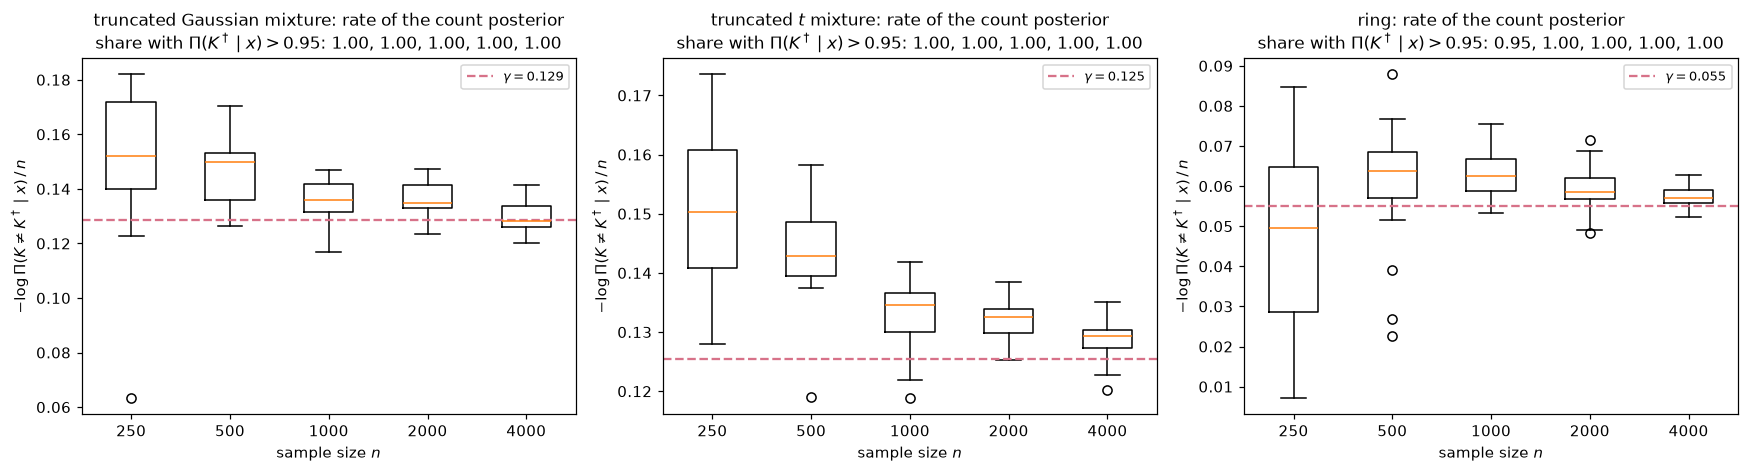

In [10]:
def lnot(o):
    lp = {k: z - o['n'] * pop[o['dgp']]['c'] * k for k, z in o['logZ'].items()}
    K = pop[o['dgp']]['K']
    return logsumexp([v for k, v in lp.items() if k != K]) - lp[K]

fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
for a, d in zip(ax, DGPS):
    R = [[-lnot(o) / n for o in full if o['dgp'] == d and o['n'] == n] for n in NS]
    a.boxplot(R, tick_labels=NS, widths=0.5)
    a.axhline(pop[d]['gamma'], c=ACC, ls='--', label=f'$\\gamma={pop[d]["gamma"]:.3f}$')
    share = [np.mean([o['pK'].get(pop[d]['K'], 0) > 0.95 for o in full if o['dgp'] == d and o['n'] == n]) for n in NS]
    a.set(xlabel='sample size $n$', ylabel=r'$-\log\Pi(K\neq K^\dagger\mid x)\,/\,n$',
          title=f'{NAME[d]}: rate of the count posterior\n' + r'share with $\Pi(K^\dagger\mid x)>0.95$: ' + ', '.join(f'{s:.2f}' for s in share))
    a.legend()
tidy(fig)

### 3c. Soft allocations only at cell boundaries

The transport plan $\Gamma^*$ between $\widehat P_n$ and $Q_\theta$ allocates each observation's mass to the representatives; $n\Gamma^*_{ij}$ is the share of $x_i$ sent to $z_j$. Below, each point is colored by its posterior-mean allocation $\bar a_{ij}=\mathbb E(n\Gamma^*_{ij}\mid x_{1:n},K=K^\dagger)$ (100 posterior draws): the color is the allocation-weighted mixture of the representatives' colors, so a point allocated entirely to one representative has that representative's pure color and a point shared between representatives has a blended color, drawn larger.
Only points near the boundaries between transport cells are shared, and the band of shared points narrows as $n$ grows because the posterior of $(z,w)$ concentrates at rate $n^{-1/2}$.

gmm share of shared points by n: [0.0775, 0.0552, 0.0399, 0.0274, 0.0198]
t share of shared points by n: [0.0427, 0.0316, 0.0218, 0.0152, 0.011]
ring share of shared points by n: [0.1395, 0.0921, 0.0654, 0.0452, 0.0321]


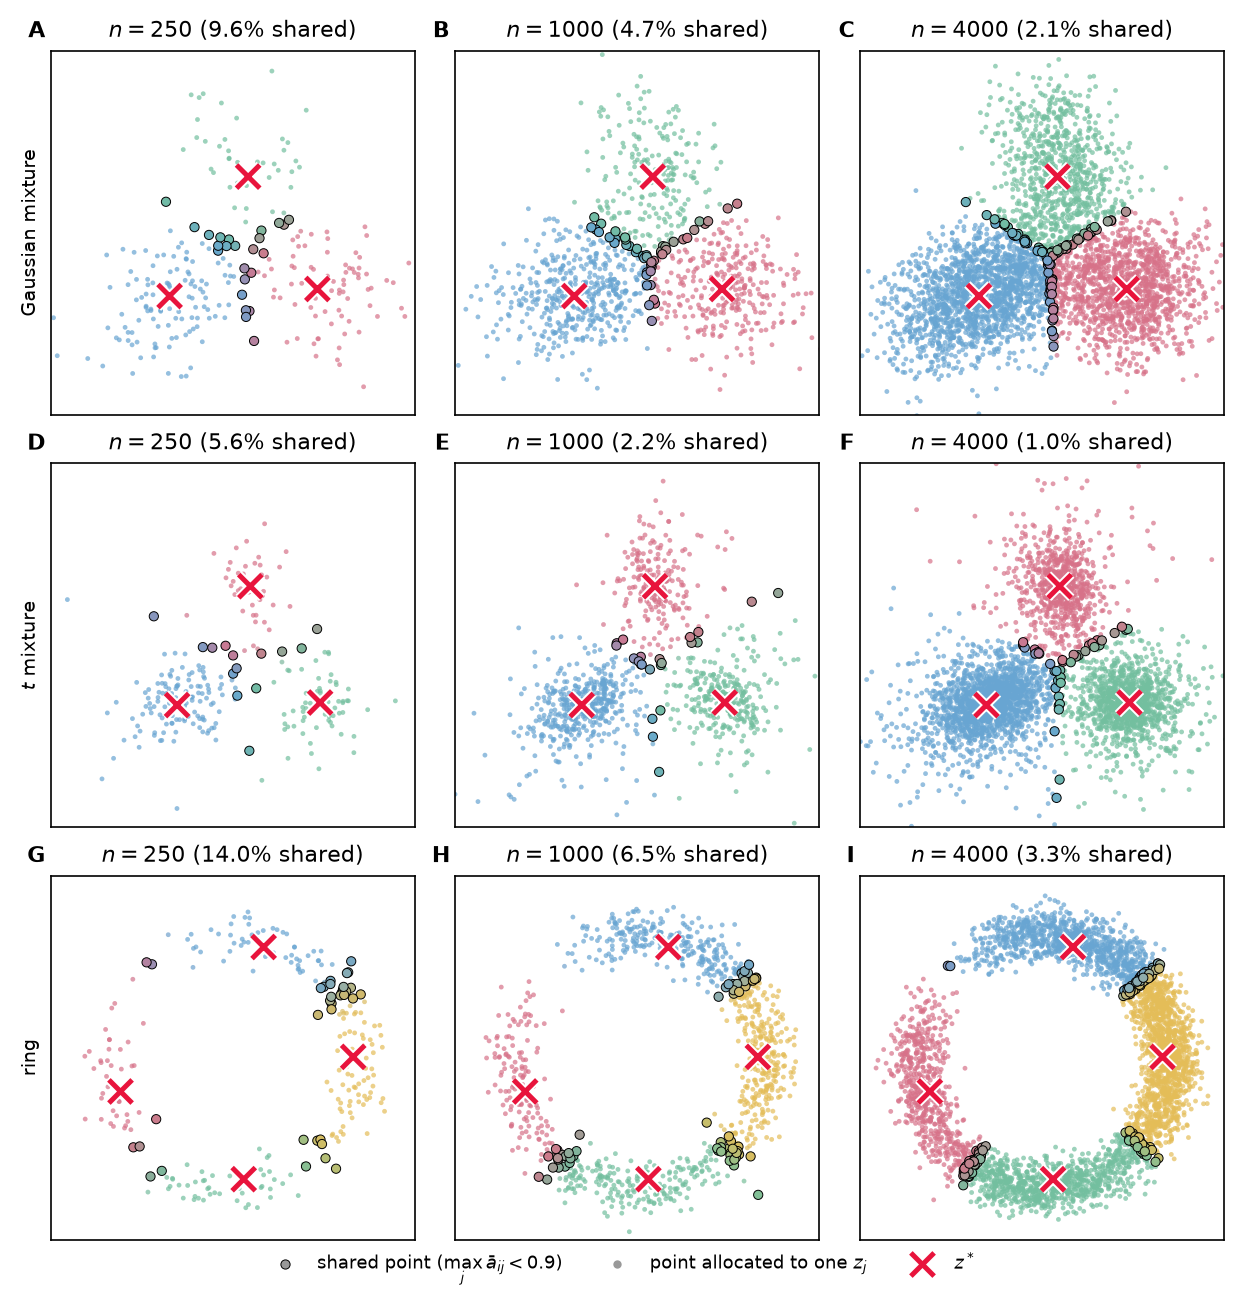

In [11]:
show = (250, 1000, 4000)
with plt.rc_context(PAPER):
    fig, ax = plt.subplots(3, 3, figsize=(W, 6.5))
    for i, d in enumerate(DGPS):
        K = pop[d]['K']
        win = window(next(o for o in main if o['dgp'] == d and o['n'] == 4000 and o['rep'] == 0)['x'], q=ZOOM[d])   # one window per row
        for a, n in zip(ax[i], show):
            o = next(o for o in main if o['dgp'] == d and o['n'] == n and o['rep'] == 0)
            A, soft = o['alloc'], o['alloc'].max(1) < 0.9
            rgb = np.clip(A @ COL[:K, :3], 0, 1)
            a.scatter(*o['x'][~soft].T, s=3, c=rgb[~soft], alpha=0.7, lw=0)
            a.scatter(*o['x'][soft].T, s=11, c=rgb[soft], edgecolor='k', linewidth=0.35)
            cross(a, pop[d]['z'])
            a.set(xticks=[], yticks=[], **win)
            a.set_title(f'$n={n}$ ({soft.mean():.1%} shared)', pad=5)
        ax[i, 0].set_ylabel(NAME[d].replace('truncated ', ''), fontsize=7)
        S = [[o['soft'] for o in main if o['dgp'] == d and o['n'] == n] for n in NS]
        print(d, 'share of shared points by n:', [round(float(np.mean(s)), 4) for s in S])
    h = [ax[0, 0].scatter([], [], s=11, c='0.6', edgecolor='k', linewidth=0.35, label=r'shared point ($\max_j\bar a_{ij}<0.9$)'),
         ax[0, 0].scatter([], [], s=4, c='0.6', label='point allocated to one $z_j$'),
         ax[0, 0].scatter([], [], marker='x', s=70, c=STAR, linewidths=1.8, label='$z^*$')]
    fig.legend(handles=h, loc='lower center', ncol=3, bbox_to_anchor=(0.5, 0.0), frameon=False)
    letters(fig); fig.tight_layout(w_pad=0.3, h_pad=1.2, rect=(0, 0.03, 1, 1))
    save(fig, 'fig_sim_alloc')

## 4. Asymptotic normality and calibrated coverage (Theorem 4)

Conditional on $K=K^\dagger$, the target is $\theta^*=(z^*,w^*_1,\dots,w^*_{K^\dagger-1})$, the $K^\dagger$ representatives and weights that best approximate $P_0$. For each data set (60 per $n$), we compute three 95% intervals for every coordinate of $\theta^*$:

* **posterior**: percentiles of the relabeled CoRP posterior draws, approximately $\widehat\theta_n\pm1.96\,\{\mathrm{diag}\,J^{-1}/(n\lambda_0)\}^{1/2}$;
* **sandwich**: percentiles of the sandwich-adjusted draws (`calibrate`), approximately $\bar\theta_n\pm1.96\,\{\mathrm{diag}\,\widehat\Omega/n\}^{1/2}$;
* **$k$-means bootstrap**: percentiles of 200 bootstrap refits of $k$-means at $K^\dagger$ (weights = Voronoi masses).

Theorem 4 predicts nominal coverage for the sandwich intervals but not for the posterior intervals, whose shape is set by $J^{-1}$ rather than $\Omega$; changing $\lambda_0$ only rescales them.

In [12]:
names = {'post': 'CoRP posterior', 'sand': 'CoRP sandwich', 'boot': '$k$-means bootstrap'}
ratio = lambda O, k: np.mean([o[f'hw_{k}'] for o in O], 0) / (1.96 * np.std([o['th_hat'] for o in O], 0))
sel = lambda d, n: [o for o in main if o['dgp'] == d and o['n'] == n]
ex = pickle.load(open('results/extra.pkl', 'rb')) + sel('gmm', 4000)     # 180 data sets for the truncated GMM at n = 4000

display(Markdown('**Table 1.** Coverage of $\\theta^*$ by 95% intervals, averaged over the coordinates of $\\theta$, and mean half-width divided by $1.96\\,\\mathrm{sd}(\\widehat\\theta_n)$ (1 = correct width), averaged over coordinates; 60 data sets per row.'))
rows = []
for d in DGPS:
    for n in NS:
        O = sel(d, n)
        rows.append([NAME[d], n] + [f'{np.mean([o[f"cov_{k}"].mean() for o in O]):.3f}' for k in names] + [f'{ratio(O, k).mean():.2f}' for k in names])
rows.append([NAME['gmm'] + ', 180 data sets', 4000] + [f'{np.mean([o[f"cov_{k}"].mean() for o in ex]):.3f}' for k in names] + [f'{ratio(ex, k).mean():.2f}' for k in names])
table(['distribution', '$n$'] + [f'coverage: {v}' for v in names.values()] + [f'width ratio: {v}' for v in names.values()], rows)
with open(f'{FIG}/tab_sim_coverage.tex', 'w') as f:                        # the same table for the paper (Supplementary Table)
    f.write('\\begin{tabular}{@{}llcccccc@{}}\n\\toprule\n& & \\multicolumn{3}{c}{coverage} & \\multicolumn{3}{c}{half-width ratio}\\\\\n'
            '\\cmidrule(lr){3-5}\\cmidrule(l){6-8}\ndistribution & $n$ & posterior & sandwich & bootstrap & posterior & sandwich & bootstrap\\\\\n\\midrule\n')
    last = None
    for r in rows:
        name = r[0].replace('truncated ', '').replace(', 180 data sets', '$^*$')
        f.write(' & '.join([name if name != last else '', f'{r[1]}'] + r[2:]) + '\\\\\n')
        last = name or last
    f.write('\\bottomrule\n\\end{tabular}\n')

for d in DGPS:
    K, O = pop[d]['K'], (ex if d == 'gmm' else sel(d, 4000))
    labels = [f'$z_{{{j + 1},{c}}}$' for j in range(K) for c in (1, 2)] + [f'$w_{{{j + 1}}}$' for j in range(K - 1)]
    display(Markdown(f'**Table 2 ({NAME[d]}, $n=4000$, {len(O)} data sets).** Coverage and width ratio by coordinate; Monte Carlo standard error of a coverage of 0.95 is {np.sqrt(.95 * .05 / len(O)):.3f}.'))
    table(['', *labels], [[f'coverage: {names[k]}', *np.round(np.mean([o[f"cov_{k}"] for o in O], 0), 2)] for k in names]
                         + [[f'width ratio: {names[k]}', *np.round(ratio(O, k), 2)] for k in names])

**Table 1.** Coverage of $\theta^*$ by 95% intervals, averaged over the coordinates of $\theta$, and mean half-width divided by $1.96\,\mathrm{sd}(\widehat\theta_n)$ (1 = correct width), averaged over coordinates; 60 data sets per row.

| distribution | $n$ | coverage: CoRP posterior | coverage: CoRP sandwich | coverage: $k$-means bootstrap | width ratio: CoRP posterior | width ratio: CoRP sandwich | width ratio: $k$-means bootstrap |
|---|---|---|---|---|---|---|---|
| truncated Gaussian mixture | 250 | 0.921 | 0.952 | 0.938 | 1.06 | 1.05 | 1.04 |
| truncated Gaussian mixture | 500 | 0.910 | 0.935 | 0.931 | 0.97 | 0.94 | 0.95 |
| truncated Gaussian mixture | 1000 | 0.912 | 0.969 | 0.965 | 1.09 | 1.05 | 1.06 |
| truncated Gaussian mixture | 2000 | 0.896 | 0.938 | 0.927 | 0.99 | 0.97 | 0.97 |
| truncated Gaussian mixture | 4000 | 0.902 | 0.948 | 0.944 | 0.98 | 0.96 | 0.96 |
| truncated $t$ mixture | 250 | 0.873 | 0.927 | 0.925 | 1.21 | 0.94 | 0.94 |
| truncated $t$ mixture | 500 | 0.865 | 0.954 | 0.942 | 1.19 | 0.96 | 0.96 |
| truncated $t$ mixture | 1000 | 0.900 | 0.954 | 0.946 | 1.21 | 1.00 | 0.99 |
| truncated $t$ mixture | 2000 | 0.898 | 0.942 | 0.942 | 1.27 | 1.03 | 1.03 |
| truncated $t$ mixture | 4000 | 0.871 | 0.975 | 0.958 | 1.25 | 1.00 | 0.99 |
| ring | 250 | 0.927 | 0.971 | 0.964 | 1.52 | 1.15 | 1.25 |
| ring | 500 | 0.926 | 0.964 | 0.965 | 1.51 | 1.05 | 1.16 |
| ring | 1000 | 0.914 | 0.955 | 0.944 | 1.56 | 1.05 | 1.06 |
| ring | 2000 | 0.902 | 0.948 | 0.942 | 1.52 | 1.01 | 0.99 |
| ring | 4000 | 0.918 | 0.962 | 0.961 | 1.61 | 1.05 | 1.04 |
| truncated Gaussian mixture, 180 data sets | 4000 | 0.902 | 0.943 | 0.938 | 0.98 | 0.96 | 0.96 |

**Table 2 (truncated Gaussian mixture, $n=4000$, 180 data sets).** Coverage and width ratio by coordinate; Monte Carlo standard error of a coverage of 0.95 is 0.016.

|  | $z_{1,1}$ | $z_{1,2}$ | $z_{2,1}$ | $z_{2,2}$ | $z_{3,1}$ | $z_{3,2}$ | $w_{1}$ | $w_{2}$ |
|---|---|---|---|---|---|---|---|---|
| coverage: CoRP posterior | 0.98 | 0.98 | 0.99 | 0.88 | 0.93 | 0.99 | 0.7 | 0.76 |
| coverage: CoRP sandwich | 0.96 | 0.94 | 0.93 | 0.95 | 0.92 | 0.97 | 0.93 | 0.94 |
| coverage: $k$-means bootstrap | 0.95 | 0.94 | 0.94 | 0.94 | 0.91 | 0.97 | 0.91 | 0.94 |
| width ratio: CoRP posterior | 1.06 | 1.24 | 1.38 | 0.81 | 0.93 | 1.34 | 0.51 | 0.57 |
| width ratio: CoRP sandwich | 0.95 | 0.93 | 0.94 | 0.95 | 0.91 | 1.05 | 0.95 | 0.96 |
| width ratio: $k$-means bootstrap | 0.98 | 0.93 | 0.95 | 0.94 | 0.92 | 1.05 | 0.94 | 0.96 |

**Table 2 (truncated $t$ mixture, $n=4000$, 60 data sets).** Coverage and width ratio by coordinate; Monte Carlo standard error of a coverage of 0.95 is 0.028.

|  | $z_{1,1}$ | $z_{1,2}$ | $z_{2,1}$ | $z_{2,2}$ | $z_{3,1}$ | $z_{3,2}$ | $w_{1}$ | $w_{2}$ |
|---|---|---|---|---|---|---|---|---|
| coverage: CoRP posterior | 1.0 | 1.0 | 1.0 | 1.0 | 1.0 | 1.0 | 0.43 | 0.53 |
| coverage: CoRP sandwich | 0.98 | 0.97 | 1.0 | 0.95 | 0.98 | 0.93 | 0.98 | 1.0 |
| coverage: $k$-means bootstrap | 0.97 | 0.95 | 0.97 | 0.95 | 0.97 | 0.93 | 0.93 | 1.0 |
| width ratio: CoRP posterior | 1.6 | 1.25 | 1.68 | 1.55 | 1.56 | 1.73 | 0.33 | 0.34 |
| width ratio: CoRP sandwich | 0.95 | 0.97 | 1.05 | 0.93 | 1.11 | 1.02 | 0.89 | 1.06 |
| width ratio: $k$-means bootstrap | 0.95 | 0.96 | 1.07 | 0.94 | 1.12 | 1.03 | 0.87 | 1.03 |

**Table 2 (ring, $n=4000$, 60 data sets).** Coverage and width ratio by coordinate; Monte Carlo standard error of a coverage of 0.95 is 0.028.

|  | $z_{1,1}$ | $z_{1,2}$ | $z_{2,1}$ | $z_{2,2}$ | $z_{3,1}$ | $z_{3,2}$ | $z_{4,1}$ | $z_{4,2}$ | $w_{1}$ | $w_{2}$ | $w_{3}$ |
|---|---|---|---|---|---|---|---|---|---|---|---|
| coverage: CoRP posterior | 1.0 | 0.95 | 0.92 | 1.0 | 0.9 | 1.0 | 1.0 | 0.93 | 0.82 | 0.77 | 0.82 |
| coverage: CoRP sandwich | 0.97 | 0.95 | 0.97 | 0.97 | 0.9 | 0.97 | 0.97 | 0.98 | 0.97 | 0.98 | 0.97 |
| coverage: $k$-means bootstrap | 0.98 | 0.95 | 0.97 | 0.93 | 0.9 | 0.97 | 0.98 | 0.98 | 0.95 | 0.97 | 0.98 |
| width ratio: CoRP posterior | 2.0 | 0.96 | 0.82 | 3.55 | 0.94 | 2.49 | 4.08 | 1.03 | 0.6 | 0.61 | 0.65 |
| width ratio: CoRP sandwich | 0.99 | 0.99 | 0.95 | 1.13 | 0.95 | 1.18 | 1.07 | 1.15 | 1.08 | 1.03 | 1.03 |
| width ratio: $k$-means bootstrap | 1.0 | 0.99 | 0.95 | 1.08 | 0.93 | 1.14 | 1.07 | 1.16 | 1.07 | 1.01 | 1.01 |

### Root-$n$ scaling and normality

Theorem 4 requires $\widehat\theta_n$ to fluctuate around $\theta^*$ at rate $n^{-1/2}$, and the posterior to be approximately normal around $\widehat\theta_n$. Left: $\sqrt n\,\mathrm{sd}(\widehat\theta_n)$ across data sets, which should be roughly constant in $n$ (one line per coordinate). Middle: $\sqrt{n\lambda_0}$ times the posterior standard deviation, which should approach $\{\mathrm{diag}\,J^{-1}\}^{1/2}$. Right: the distance between the posterior mean and $\widehat\theta_n$ in posterior standard deviations, which should tend to 0.

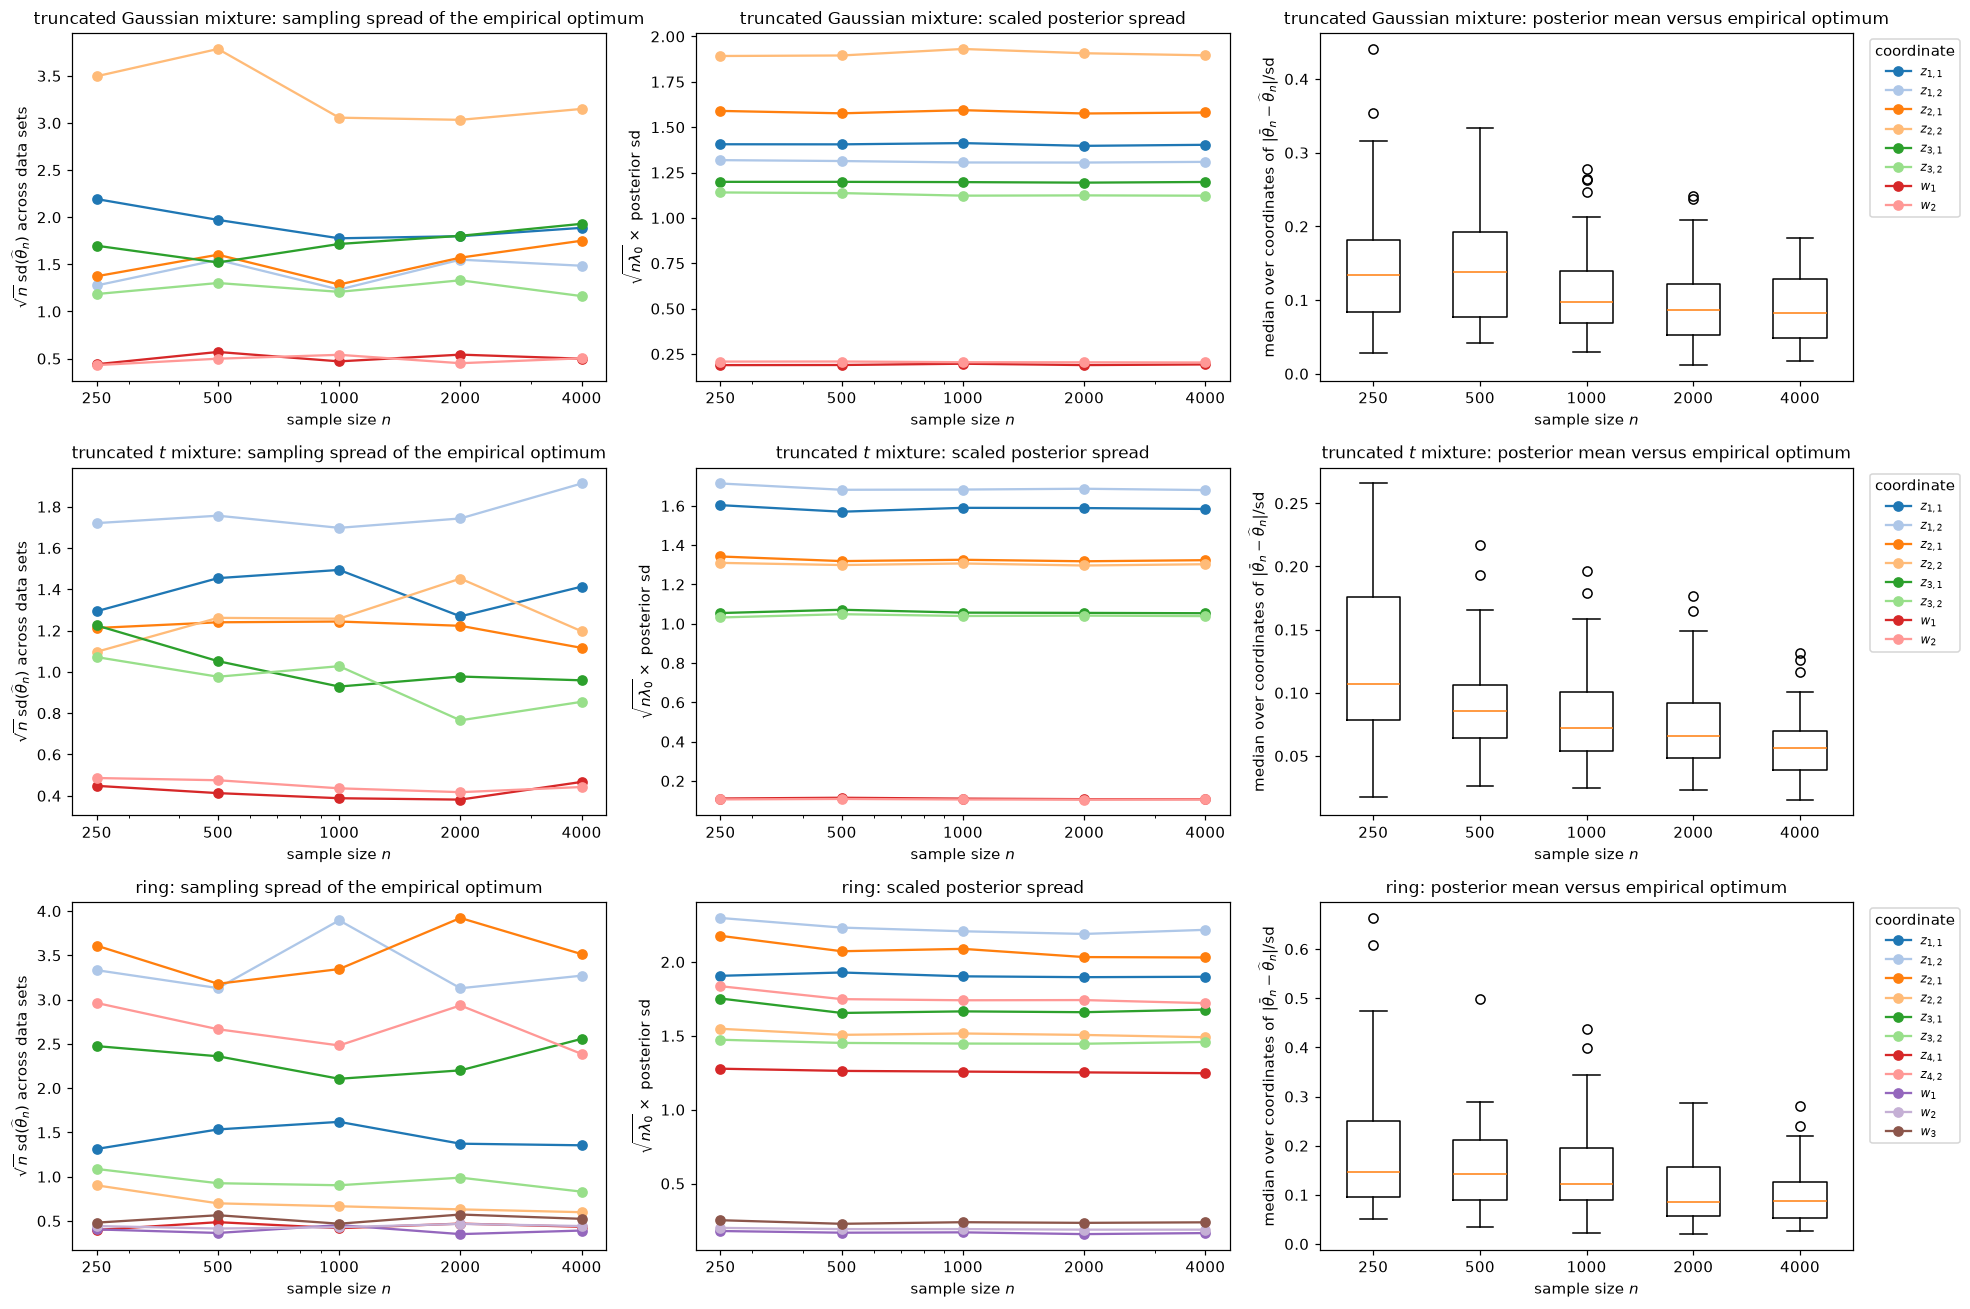

In [13]:
fig, ax = plt.subplots(3, 3, figsize=(18, 12))
for i, d in enumerate(DGPS):
    K = pop[d]['K']
    labels = [f'$z_{{{j + 1},{c}}}$' for j in range(K) for c in (1, 2)] + [f'$w_{{{j + 1}}}$' for j in range(K - 1)]
    cols = plt.cm.tab20(np.arange(len(labels)))
    O = {n: [o for o in main if o['dgp'] == d and o['n'] == n] for n in NS}
    sd_hat = np.array([np.sqrt(n) * np.std([o['th_hat'] for o in O[n]], 0, ddof=1) for n in NS])
    sd_post = np.array([np.sqrt(n * LAM0) * np.mean([o['post_sd'] for o in O[n]], 0) for n in NS])
    gap = [[np.median(np.abs(o['post_mean'] - o['th_hat']) / o['post_sd']) for o in O[n]] for n in NS]
    for k in range(len(labels)):
        ax[i, 0].plot(NS, sd_hat[:, k], 'o-', c=cols[k], label=labels[k])
        ax[i, 1].plot(NS, sd_post[:, k], 'o-', c=cols[k], label=labels[k])
    ax[i, 0].set(xscale='log', xticks=NS, xticklabels=NS, xlabel='sample size $n$', ylabel=r'$\sqrt{n}\,\mathrm{sd}(\widehat\theta_n)$ across data sets',
                 title=f'{NAME[d]}: sampling spread of the empirical optimum')
    ax[i, 1].set(xscale='log', xticks=NS, xticklabels=NS, xlabel='sample size $n$', ylabel=r'$\sqrt{n\lambda_0}\times$ posterior sd',
                 title=f'{NAME[d]}: scaled posterior spread')
    ax[i, 2].boxplot(gap, tick_labels=NS, widths=0.5)
    ax[i, 2].set(xlabel='sample size $n$', ylabel=r'median over coordinates of $|\bar\theta_n-\widehat\theta_n|/\mathrm{sd}$',
                 title=f'{NAME[d]}: posterior mean versus empirical optimum')
    ax[i, 2].legend(*ax[i, 0].get_legend_handles_labels(), title='coordinate', loc='upper left', bbox_to_anchor=(1.02, 1), fontsize=8)
tidy(fig)

## 5. Other representative points

Support points (Mak and Joseph 2018), kernel herding (Chen et al. 2010) and archetypes (Cutler and Breiman 1994) also summarize a sample by $K$ points. Each is computed at $K=K^\dagger$ on the 20 data sets per $(\text{DGP},n)$ with the full count posterior (`sim_utils.rep_job`): support points and herding with equal weights, archetypes with the weights implied by their convex combinations. Each $K^\dagger$-point measure, and the CoRP posterior mean and the $k$-means solution, is scored against 5000 draws of $P_0$ by four criteria: $W_2^2$ with the method's weights, the quantization error (each draw to its nearest point), the energy distance and the squared MMD with a Gaussian kernel (median-heuristic bandwidth). Each method minimizes its own criterion: CoRP and $k$-means the transport cost, support points the energy distance, herding the MMD, and archetypes the reconstruction error of the data by convex combinations of the points.

The figure shows the median over the 20 data sets, and the table the number of data sets in which CoRP has the smaller criterion than support points, the closest competitor.

**Median criterion at $n=250$ and $n=4000$**, and the number of the 100 data sets in which CoRP is below support points.

| distribution | criterion | CoRP, $n=250$ | CoRP, $n=4000$ | k-means, $n=250$ | k-means, $n=4000$ | support points, $n=250$ | support points, $n=4000$ | kernel herding, $n=250$ | kernel herding, $n=4000$ | archetypes, $n=250$ | archetypes, $n=4000$ | CoRP < support points |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| truncated Gaussian mixture | $W_2^2$ | 1.21 | 1.16 | 1.21 | 1.16 | 1.32 | 1.28 | 2.39 | 2.86 | 5.43 | 9.07 | 100 |
| truncated Gaussian mixture | quantization error | 1.17 | 1.15 | 1.17 | 1.15 | 1.25 | 1.21 | 2.21 | 2.6 | 5.27 | 8.97 | 100 |
| truncated Gaussian mixture | energy distance | 0.212 | 0.204 | 0.213 | 0.204 | 0.214 | 0.204 | 0.396 | 0.564 | 1.1 | 1.64 | 47 |
| truncated Gaussian mixture | squared MMD | 0.00531 | 0.00396 | 0.00535 | 0.00398 | 0.00703 | 0.00517 | 0.0376 | 0.0514 | 0.274 | 0.452 | 92 |
| truncated $t$ mixture | $W_2^2$ | 0.828 | 0.771 | 0.825 | 0.771 | 1.16 | 1.14 | 1.99 | 2.5 | 5.74 | 11 | 100 |
| truncated $t$ mixture | quantization error | 0.771 | 0.765 | 0.771 | 0.765 | 0.847 | 0.831 | 1.91 | 2.33 | 5.33 | 10.5 | 100 |
| truncated $t$ mixture | energy distance | 0.15 | 0.146 | 0.149 | 0.147 | 0.173 | 0.169 | 0.368 | 0.584 | 1.19 | 1.98 | 99 |
| truncated $t$ mixture | squared MMD | 0.00268 | 0.00179 | 0.00266 | 0.00179 | 0.00653 | 0.00549 | 0.0315 | 0.0508 | 0.295 | 0.551 | 99 |
| ring | $W_2^2$ | 0.679 | 0.623 | 0.69 | 0.622 | 0.922 | 0.855 | 1.16 | 1.2 | 1.08 | 1.35 | 100 |
| ring | quantization error | 0.622 | 0.609 | 0.622 | 0.609 | 0.72 | 0.68 | 1.05 | 1.09 | 0.967 | 1.24 | 100 |
| ring | energy distance | 0.126 | 0.12 | 0.128 | 0.12 | 0.134 | 0.129 | 0.209 | 0.21 | 0.233 | 0.318 | 89 |
| ring | squared MMD | 0.0032 | 0.00186 | 0.00304 | 0.00185 | 0.00412 | 0.00247 | 0.0122 | 0.0111 | 0.0154 | 0.0307 | 81 |

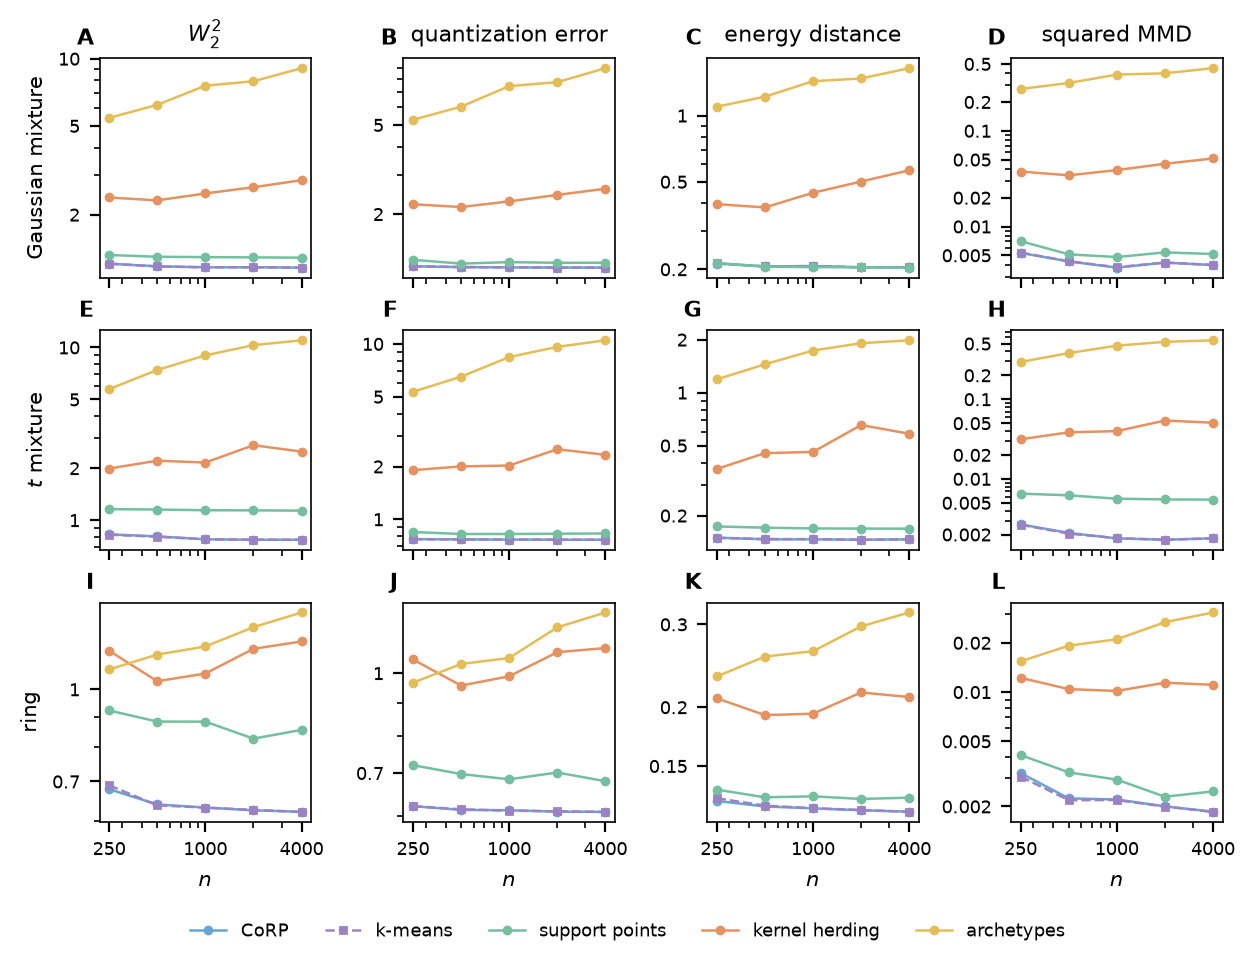

In [14]:
CRIT = {'W2': '$W_2^2$', 'quant': 'quantization error', 'energy': 'energy distance', 'mmd': 'squared MMD'}
RM = list(reps[0]['disc'])
RCOL = dict(zip(RM, (MCOL['CoRP'], MCOL['k-means'], LINE[1], LINE[5], LINE[3])))
med = lambda d, n, m, c: np.median([o['disc'][m][c] for o in reps if o['dgp'] == d and o['n'] == n])
with plt.rc_context(PAPER):
    fig, ax = plt.subplots(3, 4, figsize=(W, 4.8), sharex=True)
    for i, d in enumerate(DGPS):
        for a, c in zip(ax[i], CRIT):
            for m in RM:
                a.plot(NS, [med(d, n, m, c) for n in NS], 'o-' if m != 'k-means' else 's--', ms=2.5, lw=0.9, color=RCOL[m], label=m)
            a.set(xscale='log', yscale='log', xticks=NS[::2], xticklabels=NS[::2])
            a.yaxis.set_major_locator(LogLocator(subs=(1, 2, 5) if np.divide(*a.get_ylim()[::-1]) > 8 else (1, 1.5, 2, 3, 5, 7)))
            a.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:g}'))
            a.yaxis.set_minor_formatter(NullFormatter())
        ax[i, 0].set_ylabel(NAME[d].replace('truncated ', ''))
    for a, c in zip(ax[0], CRIT.values()):
        a.set_title(c)
    for a in ax[2]:
        a.set_xlabel('$n$')
    fig.legend(*ax[0, 0].get_legend_handles_labels(), loc='lower center', ncol=5, bbox_to_anchor=(0.5, 0.0), frameon=False)
    letters(fig); fig.tight_layout(w_pad=0.5, h_pad=0.6, rect=(0, 0.045, 1, 1))
    save(fig, 'fig_sim_rep')
display(Markdown('**Median criterion at $n=250$ and $n=4000$**, and the number of the 100 data sets in which CoRP is below support points.'))
table(['distribution', 'criterion', *[f'{m}, $n={n}$' for m in RM for n in (NS[0], NS[-1])], 'CoRP < support points'],
      [[NAME[d], CRIT[c], *[f'{med(d, n, m, c):.3g}' for m in RM for n in (NS[0], NS[-1])],
        sum(o['disc']['CoRP'][c] < o['disc']['support points'][c] for o in reps if o['dgp'] == d)] for d in DGPS for c in CRIT])

## Summary

Numbers below are from 60 data sets per $(\text{DGP}, n)$, of which the first 20 carry the full bridge-sampling count posterior.

* **Choice of $c$.** $c$ sets the resolution and $K^\dagger(c)$ is a step function of it. CoRP targets $K^\dagger(c)$, so its count reads as "the count at resolution $c$", not as a number of true components. Here $c$ is $\lambda_0$ times the geometric mean of the two cost gaps around the intended count, which uses $P_0$ and is a simulation device only.
* **Counts.** The CoRP posterior mode equals $K^\dagger$ in every data set at every $n$. The rate $-\log\Pi(K\neq K^\dagger\mid x)/n$ approaches $\gamma$ as Theorem 2 predicts: its median moves from 0.15 to 0.13 for the truncated GMM ($\gamma=0.129$), from 0.15 to 0.13 for the $t$ mixture ($\gamma=0.125$), and stays between 0.050 and 0.064 for the ring, ending at 0.057 at $n=4000$ ($\gamma=0.0549$), where $n=250$ is still pre-asymptotic (95% of data sets with $\Pi(K^\dagger\mid x)>0.95$, 100% from $n=500$ on). GMM-BIC agrees with $K^\dagger$ only for the truncated GMM (95 of 100 data sets); its count grows with $n$ for the $t$ mixture (3 to 6) and the ring (5 to 8).
* **MFM.** With its default prior the MFM selects 3 in 91 of the 100 truncated-GMM data sets. On the $t$ mixture its count ranges from 4 to 8 at every $n$ (one data set at 11), and on the ring it grows with $n$, from 5 to 7 at $n=250$ to 10 or 11 at $n=4000$, so it agrees with $K^\dagger$ only when the components are Gaussian. Its two chains have the same mode in 97, 47 and 81 of the 100 data sets per distribution and differ by one in most of the others, because the posterior of $K_+$ spreads over several counts on the $t$ mixture and the ring. With the count prior of CoRP in place of the default, the MFM selects 1 component on the truncated GMM (98 of 100 data sets), 2 on the $t$ mixture (all) and 4 on the ring (99 of 100): that prior is calibrated to the transport cost, not to a Gaussian likelihood.
* **Elbow rule and $K_{\max}$.** With $K_{\max}=16$ the Kneedle elbow is 3 in every $t$-mixture data set, 4 in every ring data set and 4 in 83 of the 100 truncated-GMM data sets (3 in the others). With $K_{\max}=8$ it is 3 in every data set of the two mixtures and in 94 of the 100 ring data sets. The CoRP count posterior does not depend on $K_{\max}$: the bridge sampler stops at $K=5$ (mixtures) or $K=6$ (ring) in all 300 data sets, and reruns with $K_{\max}=8$ give identical output.
* **Locations and weights.** Given $K^\dagger$, the CoRP posterior mean and the $k$-means solution target the same $\theta^*$. The median distance between them, in posterior standard deviations, falls from 0.11 to 0.15 at $n=250$ to 0.06 to 0.09 at $n=4000$.
* **Soft allocations.** Only points near the boundaries between transport cells are shared ($\max_j\bar a_{ij}<0.9$), and their share falls like $n^{-1/2}$: from 8% to 2% (truncated GMM), 4.3% to 1.1% ($t$ mixture), and 13.9% to 3.2% (ring) between $n=250$ and $n=4000$.
* **Uncertainty.** $\sqrt n\,\mathrm{sd}(\widehat\theta_n)$ and $\sqrt{n\lambda_0}$ times the posterior sd are both flat in $n$, as Theorem 4 requires, but they differ, so the posterior has the wrong shape. The posterior intervals over-cover most locations and under-cover the weights (down to 0.38), with average coverage 0.865 to 0.927. The sandwich intervals average 0.927 to 0.975 and track the $k$-means bootstrap (0.925 to 0.965, $B=200$ refits) within 0.017 at every $(\text{DGP}, n)$. For the truncated GMM at $n=4000$, 120 further data sets (180 in all) give 0.943 for the sandwich and 0.938 for the bootstrap, and per coordinate the sandwich coverage ranges from 0.92 to 0.97. Which coordinate is lowest changes with the random seeds, so these differences look like Monte Carlo variation around a common level of about 0.94 rather than a defect of one coordinate.
* **Other representative points.** At $K^\dagger$ and scored against $P_0$, the CoRP posterior mean and $k$-means agree on all four criteria. CoRP has lower $W_2^2$ and quantization error than support points in all 300 data sets (support points are 10 to 47% and 5 to 15% higher in the median). On the energy distance, which support points minimize, the two tie on the truncated GMM (CoRP lower in 47 of 100 data sets), and CoRP is 15% lower on the $t$ mixture and 7% lower on the ring, where the optimal weights are far from equal. Kernel herding and archetypes are 1.6 to 14 times CoRP on these three criteria.